# Track 01: Placental Cell Communication in Preeclampsia
**Starter Question 8.** What might gene activity reveal about communication between placental cells in preeclampsia?

Data: GSE203507 bulk RNA-seq (core) and Admati/Skarbianskis single-cell data (pseudobulk extension and gene browser), provided by the OpenBio 2026 Datathon.



## 0. Setup
Downloads the datathon repository and installs PyDESeq2 when running on Colab, loads the Python packages used throughout, and sets the data and results folders.

In [236]:
import warnings
os.environ["PYTHONWARNINGS"] = "ignore"   # also applies to worker processes started by PyDESeq2
warnings.filterwarnings("ignore")          # hide warnings in the output

# 0. Setup
import os, sys, subprocess
from pathlib import Path

# On Colab: clone the datathon repository and install PyDESeq2 (first run takes about a minute)
if "google.colab" in sys.modules:
    if not Path("/content/openbio-datathon-2026").exists():
        subprocess.run(["git", "clone", "-q",
                        "https://github.com/Harvard-Undergraduate-OpenBio/openbio-datathon-2026.git",
                        "/content/openbio-datathon-2026"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pydeseq2"], check=True)
    # Work from the official notebooks folder so relative paths match the official notebook
    os.chdir("/content/openbio-datathon-2026/track-01/notebooks")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

DATA_DIR = Path("../data")          # official data folder
RESULTS_DIR = Path("results")       # outputs saved here
RESULTS_DIR.mkdir(exist_ok=True)
print("Setup complete. Data folder:", DATA_DIR.resolve())

Setup complete. Data folder: /Users/jasonliu/openbio-datathon-2026/track-01/data


## 1. Pick a Question

**Our question (Starter Question 8):** What might gene activity reveal about communication between placental cells in preeclampsia?

**Sub-questions**
1. Which genes encoding signaling ligands or receptors differ between PE and control placentas? (bulk RNA-seq)
2. In which placental cell types do these differences occur? (pseudobulk extension, gene browser)
3. Exploratory: which ligand–receptor pairs between cell types change in PE? (pseudobulk extension)

**Scope and limits**
- The bulk samples (GSE203507) are early-onset PE only, so bulk results apply to early-onset PE.
- Expression patterns suggest possible cell-to-cell signaling; they do not show that signaling occurred (organizer guidance).

**Timeline note:** The comparison groups (Section 4) were set before running the differential expression test (Section 5). The starter question was finalized after an initial differential expression run.

## 2. Load and Check the Data
Confirms that the count table and the metadata can be matched correctly and that the counts meet the input requirements of differential expression analysis. Data files are not edited; any failed check is recorded and reported to the organizers.

### 2.1 Load and integrity checks
Loads the count table (genes × samples) and the metadata (one row per sample), then checks that:
- every sample appears in both tables, so group labels are assigned correctly;
- counts are nonnegative whole numbers, as required for DESeq2, which models raw counts;
- there are no duplicate genes or samples.

Metadata rows are then reordered to match the count columns.

In [237]:
# 2.1 Load the count table and metadata, then check that they fit together

def load_table(path):
    # Return None if the file is missing or empty (pending release)
    if not path.exists() or path.stat().st_size == 0:
        print(f"{path.name}: pending release (file is empty for now).")
        return None
    # First column holds gene IDs (counts) or sample IDs (metadata)
    return pd.read_csv(path, index_col=0)

counts = load_table(DATA_DIR / "track01_counts_vt.csv")      # genes x samples
metadata = load_table(DATA_DIR / "track01_metadata_vt.csv")  # samples x clinical fields

if counts is not None and metadata is not None:
    print(f"Counts: {counts.shape[0]:,} genes x {counts.shape[1]} samples")
    print(f"Metadata: {metadata.shape[0]} samples x {metadata.shape[1]} fields")
    print()
    # Every sample must appear in both tables, otherwise labels are wrong
    print("Samples in both tables:      ", len(set(counts.columns) & set(metadata.index)))
    # DESeq2 models raw counts, which must be nonnegative whole numbers
    print("Counts are nonnegative:      ", bool((counts.values >= 0).all()))
    print("Counts are whole numbers:    ", bool((counts.values % 1 == 0).all()))
    # Duplicates would count the same gene or sample twice
    print("Duplicate genes:             ", int(counts.index.duplicated().sum()))
    print("Duplicate samples:           ", int(counts.columns.duplicated().sum()))
    # Put metadata rows in the same order as the count columns
    metadata = metadata.loc[counts.columns]

Counts: 26,485 genes x 30 samples
Metadata: 30 samples x 20 fields

Samples in both tables:       30
Counts are nonnegative:       True
Counts are whole numbers:     True
Duplicate genes:              0
Duplicate samples:            0


### 2.2 Metadata overview
Summarizes each metadata field with an example value, the number of missing values, and the number of distinct values. Fields with missing values cannot be used as covariates without dropping samples.

In [238]:
# 2.2 Summarize each metadata field: an example value, missing values and number of distinct values
if metadata is not None:
    overview = pd.DataFrame({
        "example_value": metadata.iloc[0],     # value in the first sample
        "n_missing": metadata.isna().sum(),    # samples with no value
        "n_unique": metadata.nunique(),        # distinct values (missing excluded)
    })
    display(overview)

,example_value,n_missing,n_unique
geo_accession,GSM6175116,0,30
donor_id,S01,0,30
group,EOPE+FGR,0,5
pe_status,PE,0,2
pe_onset,early_onset,0,2
fgr_status,FGR,0,2
control_type,not_control,0,3
ga_delivery_source,33.4,0,23
ga_delivery_completed_weeks,33,0,10
ga_delivery_extra_days,4,0,8


### 2. Results
- **Integrity:** 26,485 genes × 30 samples; 20 metadata fields. All samples appear in both tables; counts are nonnegative whole numbers; no duplicates. No check failed.
- **Missing values:** Only birthweight and blood pressure fields have missing values (5 samples each). All other fields, including `pe_status`, `fgr_status` and `ga_delivery_weeks`, are complete and can be used as covariates without dropping samples.

## 3. Explore the Samples
Describes the sample composition and the largest sources of variation in gene activity before any test is run. This shows whether PE is linked to the main patterns, and whether other variables, such as gestational age, line up with the same patterns.

**Note on sequencing batch:** Batch is not included in the provided metadata and is not analyzed here. According to the original study (Ackerman et al., medRxiv 2023, doi:10.1101/2023.03.08.23286998), the preterm birth and term birth control samples were sequenced together with four EOPE samples (S16, S20, S21, S22). Any batch effect therefore overlaps with control status and cannot be assessed with the provided data. This is reported as a limitation.

### 3.1 Sample composition
Based on the overview in 2.2, the metadata contain three kinds of fields:
- **Identifiers** (`geo_accession`, `donor_id`): one value per sample, not summarized.
- **Categorical fields** (2 to 5 levels): `group`, `pe_status`, `pe_onset`, `fgr_status`, `control_type`, `preterm_delivery`, `fetal_sex`, `qc_flags`.
- **Numeric fields**: `gestational age`, `maternal age`, `birthweight` and `blood pressure`.

This step counts samples in each level of the categorical fields, and summarizes gestational age at delivery by group to see how delivery timing overlaps with disease groups.

In [239]:
# 3.1 Sample composition
# Categorical fields identified from the 2.2 overview (2 to 5 distinct values each)
CATEGORICAL_FIELDS = ["group", "pe_status", "pe_onset", "fgr_status",
                      "control_type", "preterm_delivery", "fetal_sex", "qc_flags"]
for col in CATEGORICAL_FIELDS:
    # dropna=False keeps missing values visible as their own level
    print(col, metadata[col].value_counts(dropna=False).to_dict())
print()

# Gestational age at delivery by group
display(metadata.groupby("group")["ga_delivery_weeks"]
        .agg(["count", "mean", "min", "max"]).round(1))

group {'EOPE': 8, 'EOPE+FGR': 7, 'FGR': 5, 'iPTB': 5, 'TB': 5}
pe_status {'PE': 15, 'no_PE': 15}
pe_onset {'early_onset': 15, 'not_applicable': 15}
fgr_status {'no_FGR': 18, 'FGR': 12}
control_type {'not_control': 20, 'preterm_birth': 5, 'term_birth': 5}
preterm_delivery {'yes': 25, 'no': 5}
fetal_sex {'female': 15, 'male': 15}
qc_flags {'none': 22, 'bp_missing;birthweight_missing': 4, 'no_pe_with_bp_ge_140_90': 2, 'pe_without_bp_ge_140_90': 1, 'ga_days_component_gt6;bp_missing;birthweight_missing': 1}



,count,mean,min,max
group,,,,
EOPE,8,29.8,26.0,33.0
EOPE+FGR,7,30.7,26.6,33.7
FGR,5,29.1,26.7,30.4
TB,5,39.2,39.0,39.4
iPTB,5,31.5,29.9,33.0


### 3.1 Results
- **Groups:** EOPE 8, EOPE+FGR 7, FGR 5, iPTB 5, TB 5 (PE 15, no_PE 15). FGR occurs in both PE (7) and no_PE (5) samples.
- **Timing:** All PE samples are early onset. 25 of 30 samples are preterm; only the 5 TB samples are term.
- **Gestational age (weeks, mean [range]):** EOPE 29.8 [26.0–33.0], EOPE+FGR 30.7 [26.6–33.7], FGR 29.1 [26.7–30.4], iPTB 31.5 [29.9–33.0], TB 39.2 [39.0–39.4]. iPTB overlaps the PE groups, but no control was delivered before 29.9 weeks.
- **QC flags:** 22 samples have none; 5 lack blood pressure and birthweight data; 3 have blood pressure inconsistent with their PE label.

### 3.2 Principal component analysis
Each sample has values for 26,485 genes, too many to compare directly. PCA summarizes each sample along a few directions (principal components) that capture the largest differences between samples. Following the official workflow, we use it before any test to see:
1. whether PE and control samples differ in overall gene activity;
2. whether other variables, such as gestational age, line up with the same patterns;
3. whether there are outlying samples or unexplained clusters.

PCA is used because it is linear and deterministic, and each component comes with the share of variation it explains. It is computed on log2 counts per million, the same transformation as the official notebook, and colored by the fields in the official workflow list. Plots are used as observations only, as in the original study, which also assessed sample relationships visually with PCA and hierarchical clustering.

Variance explained: {'PC1': '20.9%', 'PC2': '12.5%', 'PC3': '9.1%', 'PC4': '8.5%', 'PC5': '4.9%'}


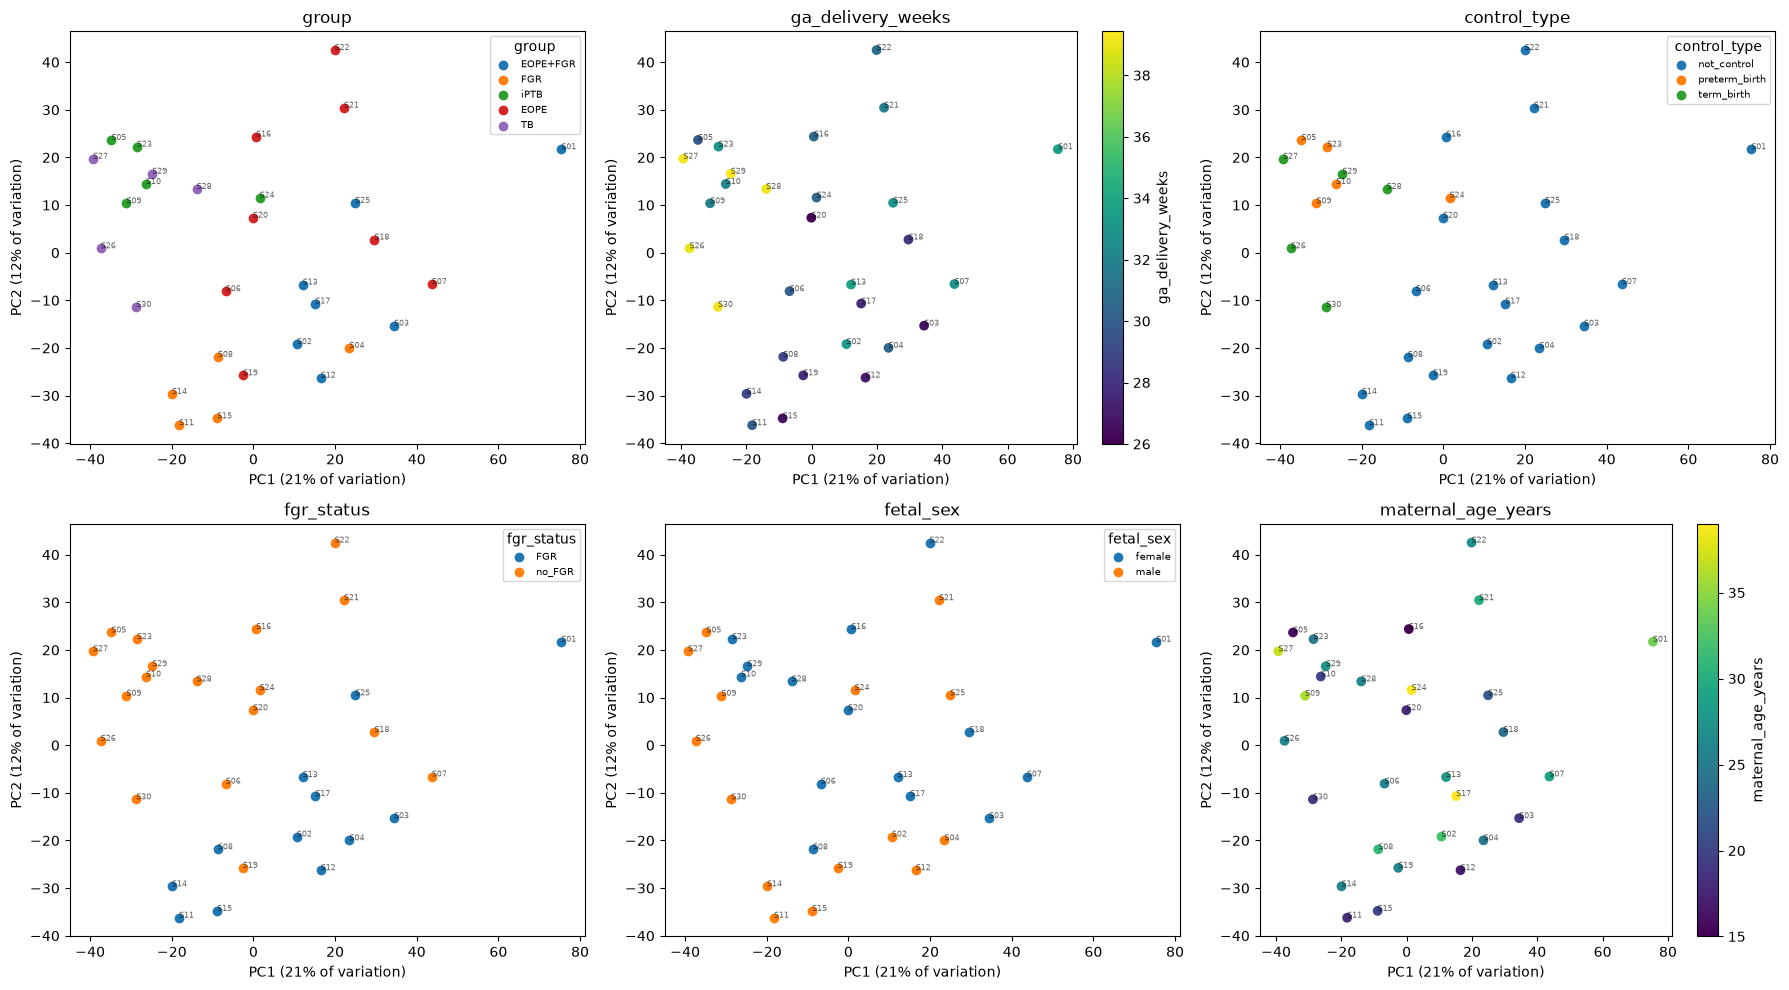

In [240]:
# 3.2 PCA on log2 counts per million
def compute_pca(counts, n_components=5):
    # Scale each sample to counts per million, then log2(+1) so a few very high genes do not dominate
    log_cpm = np.log2(counts.div(counts.sum(axis=0), axis=1) * 1e6 + 1)
    pca = PCA(n_components=n_components)
    scores = pca.fit_transform(log_cpm.T)  # samples as rows
    scores = pd.DataFrame(scores, index=counts.columns,
                          columns=[f"PC{i+1}" for i in range(n_components)])
    return scores, pca.explained_variance_ratio_

pc_scores, pc_var = compute_pca(counts)
print("Variance explained:", {f"PC{i+1}": f"{v:.1%}" for i, v in enumerate(pc_var)})

def plot_pca(scores, var, metadata, color_by, ax):
    values = metadata.loc[scores.index, color_by]
    if pd.api.types.is_numeric_dtype(values):
        # Continuous field: color gradient
        pts = ax.scatter(scores["PC1"], scores["PC2"], c=values, cmap="viridis")
        plt.colorbar(pts, ax=ax, label=color_by)
    else:
        # Categorical field: one color per level
        for level in values.fillna("NA").unique():
            mask = (values.fillna("NA") == level).values
            ax.scatter(scores.loc[mask, "PC1"], scores.loc[mask, "PC2"], label=str(level))
        ax.legend(title=color_by, fontsize=7)
    for s in scores.index:
        ax.annotate(s.replace("_VT", ""), (scores.loc[s, "PC1"], scores.loc[s, "PC2"]),
                    fontsize=6, alpha=0.6)
    ax.set_xlabel(f"PC1 ({var[0]:.0%} of variation)")
    ax.set_ylabel(f"PC2 ({var[1]:.0%} of variation)")
    ax.set_title(color_by)

# Fields from the official workflow list
COLOR_FIELDS = ["group", "ga_delivery_weeks", "control_type",
                "fgr_status", "fetal_sex", "maternal_age_years"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, field in zip(axes.flat, COLOR_FIELDS):
    plot_pca(pc_scores, pc_var, metadata, field, ax)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "pca_panels.png", dpi=300)
plt.show()

### 3.2 Results
PC1 and PC2 explain 20.9% and 12.5% of the variation.

- All 10 controls (iPTB and TB) lie on the left of PC1, and most PE samples lie to the right. Preterm controls sit with term controls rather than with PE samples of similar gestational age.
- 10 of 12 FGR samples have negative PC2 scores.
- Fetal sex and maternal age show no visible pattern.
- S01 lies far to the right on PC1 (checked in 3.3).

The control clustering may partly reflect sequencing batch (see note above). No controls are available at the earliest gestational ages, so gestational age is included as a covariate in Section 4.

### 3.3 Outlier check
S01 lies far from the other samples on PC1. Following the official workflow, we check its clinical profile and total read count here. Running the analysis with and without S01 is done in Section 6.3. No sample is removed at this stage.

In [241]:
# 3.3 Outlier check for S01
lib_size = counts.sum(axis=0).sort_values()  # total reads per sample
print("Lowest 5 total read counts:")
print(lib_size.head().to_string())
print()
print("S01 rank by total reads (1 = lowest):", lib_size.index.get_loc("S01_VT") + 1, "of", len(lib_size))
print()

# How far S01 lies from the other samples on PC1, in standard deviations
pc1 = pc_scores["PC1"]
print("S01 PC1 z-score:", round((pc1["S01_VT"] - pc1.mean()) / pc1.std(), 2))

# Clinical profile of S01
display(metadata.loc[["S01_VT"]].T)

Lowest 5 total read counts:
S22_VT    5594250
S01_VT    6849091
S12_VT    7319849
S27_VT    8102992
S05_VT    9282852

S01 rank by total reads (1 = lowest): 2 of 30

S01 PC1 z-score: 2.76


,S01_VT
geo_accession,GSM6175116
donor_id,S01
group,EOPE+FGR
pe_status,PE
pe_onset,early_onset
fgr_status,FGR
control_type,not_control
ga_delivery_source,33.4
ga_delivery_completed_weeks,33
ga_delivery_extra_days,4


### Section 3 Summary
- **Gestational age:** PE samples are all preterm, and no control was delivered before 29.9 weeks. Gestational age is included as a covariate in Section 4.
- **FGR:** FGR occurs in both PE and no_PE samples and lines up with PC2. It is included as a covariate in Section 4.
- **Fetal sex and maternal age:** No visible pattern in the PCA; not included as covariates. Fetal sex, which the original study adjusted for, is tested in Section 6.3.
- **Sequencing batch:** Not in the provided data; reported as a limitation.
- **S01:** Kept; results with and without S01 are compared in Section 6.3.

## 4. Choose a Comparison
Defines the two groups to compare and the covariates to adjust for, based on the observations in Section 3. These choices were made before running the test in Section 5.

- **Comparison:** PE (EOPE and EOPE+FGR, n = 15) vs no_PE (FGR, iPTB and TB, n = 15), using `pe_status`.
- **Covariates:** `ga_delivery_weeks` and `fgr_status`.

**Why these choices**
- PE vs no_PE uses all 30 samples and matches the research question.
- Gestational age is adjusted for because all PE samples are preterm and no control was delivered before 29.9 weeks (3.1). It is used as a continuous variable to keep the full information, rather than the binary `preterm_delivery`.
- FGR is adjusted for because it occurs in both PE and no_PE samples and lines up with PC2 (3.2), so the PE effect can be estimated separately from FGR.
- Fetal sex is not included because it showed no visible pattern in the PCA. The original study adjusted for fetal sex, so this is tested in Section 6.3.

In [242]:
# 4. Choose the comparison and covariates (set before running Section 5)
GROUP_COLUMN = "pe_status"
CASE = "PE"
CONTROL = "no_PE"
COVARIATES = ["ga_delivery_weeks", "fgr_status"]

def build_comparison(counts, metadata):
    if None in (GROUP_COLUMN, CASE, CONTROL):
        print("Fill in GROUP_COLUMN, CASE and CONTROL above, then rerun this cell.")
        return None, None
    used = [GROUP_COLUMN] + list(COVARIATES)
    # Keep only samples in the CASE or CONTROL group, and only the columns used in the model
    meta = metadata[metadata[GROUP_COLUMN].isin([CASE, CONTROL])][used].copy()
    n_before = len(meta)
    # Samples missing any model variable are dropped (DESeq2 needs complete covariates)
    meta = meta.dropna()
    if len(meta) < n_before:
        print(f"Note: {n_before - len(meta)} sample(s) dropped for missing values in {used}. Report this.")
    meta[GROUP_COLUMN] = meta[GROUP_COLUMN].astype(str)
    print(meta[GROUP_COLUMN].value_counts().to_string())
    return counts[meta.index], meta

comp_counts, comp_meta = build_comparison(counts, metadata)

# Check that FGR is present in both groups, so its effect can be separated from PE
print()
print(pd.crosstab(comp_meta[GROUP_COLUMN], comp_meta["fgr_status"]))

pe_status
PE       15
no_PE    15

fgr_status  FGR  no_FGR
pe_status              
PE            7       8
no_PE         5      10


### 4. Results
- **Sample size:** 15 PE and 15 no_PE samples. No samples were dropped, because gestational age and FGR status have no missing values (see 2.2).
- **FGR in both groups:** FGR appears in both the PE and no_PE groups, so the model can separate the effect of PE from the effect of FGR.

| | FGR | no FGR |
|---|---|---|
| PE | 7 | 8 |
| no_PE | 5 | 10 |

## 5. Run the Test
Runs differential expression with PyDESeq2, the Python implementation of DESeq2 used in the official notebook. DESeq2 models raw counts with a negative binomial distribution, adjusts for sequencing depth, and tests each gene for a difference between PE and no_PE after accounting for gestational age and FGR. The original study also used DESeq2. P-values are adjusted for testing many genes with the Benjamini-Hochberg method.

Design: `~ga_delivery_weeks + fgr_status + pe_status`

In [243]:
# 5. Run differential expression with PyDESeq2
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

results = None
if comp_counts is not None:
    # Build the model formula: covariates first, the tested variable (pe_status) last
    design = "~" + " + ".join(list(COVARIATES) + [GROUP_COLUMN])
    print("Design:", design)

    # Set up the dataset: raw integer counts and the metadata for the 30 samples
    dds = DeseqDataSet(
        counts=comp_counts.T.astype(int),   # PyDESeq2 wants samples as rows, genes as columns
        metadata=comp_meta,
        design=design,
        quiet=True,                          # hide progress messages
    )

    # Fit the model: normalize for sequencing depth (size factors),
    # estimate gene-wise variability (dispersion), and fit the negative binomial model
    dds.deseq2()

    # Test PE vs no_PE for every gene (Wald test), then adjust p-values for multiple testing
    stats = DeseqStats(dds, contrast=[GROUP_COLUMN, str(CASE), str(CONTROL)], quiet=True)
    stats.summary()

    # Sort genes by adjusted p-value and save the full table
    results = stats.results_df.sort_values("padj")
    results.to_csv(RESULTS_DIR / "de_results.csv")
    print(f"Tested {len(results):,} genes. Saved to results/de_results.csv")
    display(results.head(10))   # top 10 genes

Design: ~ga_delivery_weeks + fgr_status + pe_status
Tested 26,485 genes. Saved to results/de_results.csv


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene,,,,,,
ENG,6068.654828,2.010122,0.215836,9.313208,1.240287e-20,2.123000e-16
AMD1,3435.425862,0.816932,0.109709,7.446333,9.597057e-14,8.213641e-10
MFAP5,2830.035549,0.845775,0.116092,7.285354,3.208261e-13,1.005738e-09
TMEM45A,279.253895,2.180765,0.300326,7.261335,3.832873e-13,1.005738e-09
GPIHBP1,83.041584,1.965968,0.268112,7.332648,2.256491e-13,1.005738e-09
ABCA7,161.833727,1.363321,0.187998,7.251791,4.112969e-13,1.005738e-09
SERPINA3,418.561690,5.532783,0.761563,7.265036,3.729381e-13,1.005738e-09
FLT1,98369.836503,2.596752,0.376842,6.890818,5.547266e-12,1.186907e-08
HTRA4,7503.856778,2.714791,0.398397,6.814280,9.473725e-12,1.801797e-08


## 6. Read the Results
Sets the cutoffs that define differentially expressed genes, checks how much the result depends on the cutoff choice, and checks how reliable the estimates of the passing genes are.


### 6.1 Cutoffs and volcano plot
Any cutoff is a choice, so we compare three settings to see whether our conclusions depend on it.

- **padj < 0.05.** With Benjamini-Hochberg adjustment, this keeps the expected proportion of false discoveries among the passing genes at about 5%. We use the gene list for cell-type interpretation in later sections, so we prefer fewer false hits over a longer list. The original study used FDR < 0.1, which allows about twice as many false discoveries.
- **|log2 fold change| ≥ 1.** Statistical significance depends on sample size and variability, not on how large a difference is, so very small changes can still be significant. A fold-change cutoff restricts the list to genes that differ at least two-fold. The two-fold value is a convention rather than a biological threshold, which is why we also report results without it.

In [244]:
# 6.1a Compare three cutoff settings
CUTOFF_GRID = [(0.05, 0), (0.05, 1), (0.01, 1)]   # (padj cutoff, |log2FC| cutoff)
rows = []
for padj_c, lfc_c in CUTOFF_GRID:
    # Genes with missing padj (filtered by DESeq2) never pass
    keep = (results["padj"] < padj_c) & (results["log2FoldChange"].abs() >= lfc_c)
    passed = results[keep]
    rows.append({"padj_cutoff": padj_c, "lfc_cutoff": lfc_c,
                 "n_pass": len(passed),
                 "n_up": int((passed["log2FoldChange"] > 0).sum()),     # higher in PE
                 "n_down": int((passed["log2FoldChange"] < 0).sum())})  # lower in PE
cutoff_table = pd.DataFrame(rows)
cutoff_table.to_csv(RESULTS_DIR / "cutoff_comparison.csv", index=False)
display(cutoff_table)
print("Genes with an adjusted p-value:", int(results["padj"].notna().sum()), "of", len(results))

,padj_cutoff,lfc_cutoff,n_pass,n_up,n_down
0,0.05,0,1763,1027,736
1,0.05,1,348,258,90
2,0.01,1,232,183,49


Genes with an adjusted p-value: 17117 of 26485


### 6.1a Results
- 17,117 of 26,485 genes received an adjusted p-value; the rest were filtered out by DESeq2.
- Adding the two-fold cutoff reduces significant genes from 1,762 to 348, so most significant genes have small fold changes.
- Genes higher in PE outnumber genes lower in PE under every setting, and tightening padj to 0.01 still keeps about two thirds of the genes (232).

348 genes pass (258 higher in PE, 90 lower).


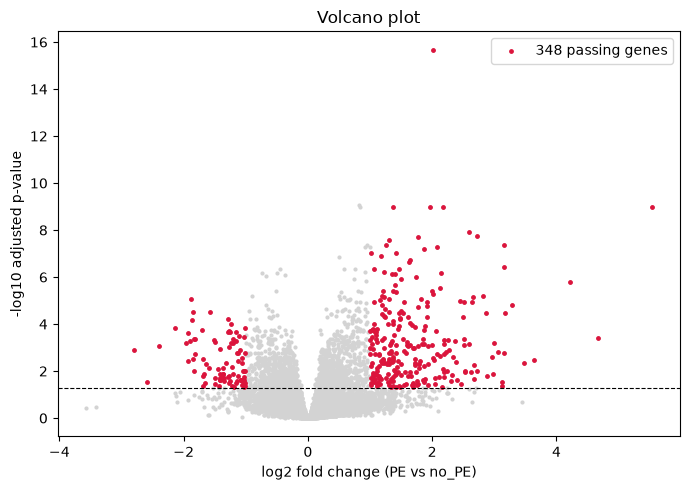

In [245]:
# 6.1b Main cutoff and volcano plot
PADJ_CUTOFF = 0.05   # adjusted p-value
LFC_CUTOFF = 1       # |log2 fold change|, i.e. at least two-fold

def passing_genes(results):
    keep = (results["padj"] < PADJ_CUTOFF) & (results["log2FoldChange"].abs() >= LFC_CUTOFF)
    return results[keep]

def volcano(results, hits):
    fig, ax = plt.subplots(figsize=(7, 5))
    # Very small p-values are clipped so they can be plotted on a log scale
    y = -np.log10(results["padj"].clip(lower=1e-300))
    ax.scatter(results["log2FoldChange"], y, s=4, color="lightgray")
    ax.scatter(hits["log2FoldChange"], -np.log10(hits["padj"].clip(lower=1e-300)),
               s=6, color="crimson", label=f"{len(hits)} passing genes")
    ax.axhline(-np.log10(PADJ_CUTOFF), ls="--", lw=0.8, color="black")   # padj cutoff
    ax.legend()
    ax.set_xlabel(f"log2 fold change ({CASE} vs {CONTROL})")
    ax.set_ylabel("-log10 adjusted p-value")
    ax.set_title("Volcano plot")
    plt.tight_layout()
    fig.savefig(RESULTS_DIR / "volcano.png", dpi=300)
    plt.show()

hits = passing_genes(results)
print(f"{len(hits)} genes pass ({(hits['log2FoldChange'] > 0).sum()} higher in {CASE}, "
      f"{(hits['log2FoldChange'] < 0).sum()} lower).")
hits.to_csv(RESULTS_DIR / "passing_genes.csv")
volcano(results, hits)

### 6.1b Results
Under the main cutoff (padj < 0.05, |log2FC| ≥ 1), 348 genes pass: 258 higher in PE and 90 lower. The volcano plot is lopsided toward genes higher in PE. The most significant gene is ENG (top point, padj 2.1 × 10⁻¹⁶).

### 6.2 Reliability of passing genes
A gene can pass the cutoffs and still have an unreliable estimate. We check two sources of uncertainty.

- **Low counts.** When a gene has very few reads, random sampling alone causes large relative fluctuations, so its fold change is unstable. We flag passing genes with baseMean below 10, a commonly used rule of thumb.
- **Uncertain effect size.** DESeq2 reports a standard error (lfcSE) for each log2 fold change. We compute an approximate 95% confidence interval (log2 fold change ± 1.96 × lfcSE) and count genes whose interval reaches below a two-fold difference. For these genes the difference is significant, but the data cannot confirm that it is at least two-fold.

In [246]:
# 6.2 Reliability checks for passing genes

# a. Low counts: flag baseMean below 10
low_count = hits[hits["baseMean"] < 10]
print("Passing genes with baseMean < 10:", len(low_count))

# b. Uncertain effect size: lower end of the approximate 95% CI of |log2FC|
ci_low = hits["log2FoldChange"].abs() - 1.96 * hits["lfcSE"]
print("Passing genes whose 95% CI reaches below a two-fold difference:",
      int((ci_low < 1).sum()), "of", len(hits))

# Genes with the least certain effect size
display(hits.assign(ci_low_abs_lfc=ci_low.round(2))
            .sort_values("ci_low_abs_lfc")[["baseMean", "log2FoldChange", "lfcSE", "padj", "ci_low_abs_lfc"]]
            .head(10))

# c. Robust list: adequate counts and a CI that stays above two-fold
robust_hits = hits[(hits["baseMean"] >= 10) & (ci_low >= 1)]
print(f"Robust passing genes: {len(robust_hits)} "
      f"({(robust_hits['log2FoldChange'] > 0).sum()} higher in PE, "
      f"{(robust_hits['log2FoldChange'] < 0).sum()} lower)")
robust_hits.to_csv(RESULTS_DIR / "robust_passing_genes.csv")

Passing genes with baseMean < 10: 81
Passing genes whose 95% CI reaches below a two-fold difference: 260 of 348


,baseMean,log2FoldChange,lfcSE,padj,ci_low_abs_lfc
gene,,,,,
FAM86HP,6.133799,-1.029738,0.366820,0.048980,0.31
PLXNA4,131.896926,-1.005789,0.351735,0.043725,0.32
RNF17,103.230905,1.008188,0.346783,0.039451,0.33
BTBD11,25.413162,-1.028277,0.358059,0.042697,0.33
MYH13,7.105564,-1.054983,0.362646,0.039365,0.34
HSD3BP4,20.280298,1.111359,0.386792,0.042635,0.35
CRNDE,16.105638,-1.006397,0.335384,0.031926,0.35
TMEM38A,5.269618,1.023603,0.342541,0.032737,0.35
AMN,4.252724,-1.181711,0.416818,0.045860,0.36


Robust passing genes: 65 (58 higher in PE, 7 lower)


### 6.2 Results
- **Low counts:** 81 of 348 passing genes (23%) have baseMean below 10.
- **Uncertain effect size:** For 260 of 348 passing genes (75%), the 95% confidence interval of the fold change reaches below two-fold. The least certain genes have log2 fold changes close to 1, and several also have low baseMean.
- **Robust list:** 65 genes have baseMean ≥ 10 and a confidence interval that stays above two-fold (58 higher in PE, 7 lower).

Most passing genes are significantly different but sit close to the two-fold cutoff, so the number of passing genes depends strongly on that cutoff. Genes for interpretation in Section 7 are chosen from the robust list.

### 6.3 Robustness checks (Sensitivity analyses)
Sensitivity analyses: they test whether the conclusions change when key assumptions or analysis choices are varied, such as outliers, group definitions and model covariates (Thabane et al., 2013, BMC Med Res Methodol). Each check changes one condition and reruns DESeq2.

| Check | What changes | Why | Basis |
|---|---|---|---|
| a. Without S01 | Remove S01 | S01 lies far from other samples on PC1 (3.3). With 15 samples per group, one extreme sample can shift the estimated differences. | Outlier sensitivity (Thabane et al., 2013) |
| b. EOPE vs iPTB | Compare only EOPE (n = 8) and iPTB (n = 5) | Both are preterm with overlapping gestational age (3.1) and neither has FGR, so the comparison does not rely on modeling either variable. | Original study design (Ackerman et al., 2023) |
| c. Without label-inconsistent samples | Remove 3 samples whose blood pressure conflicts with their PE label | Misclassified samples could distort the PE vs no_PE difference. | Our observation (2.2, 3.1) |
| d. Adding fetal sex | Add `fetal_sex` as a covariate | Genes on the sex chromosomes differ between male and female samples, and fetal sex is unevenly distributed between groups. | Original study model (Ackerman et al., 2023) |
| e. Without FGR | Adjust for gestational age only | The causal direction between FGR and PE is not established. If PE contributes to FGR, adjusting for FGR removes part of the PE difference. | Ackerman et al., 2023 |

Checks a to e were chosen based on observations in Sections 2 and 3 and on the original study. Checks a to c use fewer samples, which reduces statistical power, so fewer genes are expected to pass. We therefore focus on whether the main passing genes keep the same direction of change, and whether the robust genes (6.2) still pass.


In [247]:
# 6.3.0 Helper functions for the robustness checks
def run_deseq(counts_sub, meta_sub, covariates, group_col, case, control):
    """Run PyDESeq2 with the same settings as Section 5 and return the results table."""
    design = "~" + " + ".join(list(covariates) + [group_col])
    dds = DeseqDataSet(counts=counts_sub.T.astype(int), metadata=meta_sub,
                       design=design, quiet=True)
    dds.deseq2()
    stats = DeseqStats(dds, contrast=[group_col, case, control], quiet=True)
    stats.summary()
    return stats.results_df

def passes(res):
    """Genes passing the main cutoffs in a results table."""
    return res[(res["padj"] < PADJ_CUTOFF) & (res["log2FoldChange"].abs() >= LFC_CUTOFF)]

checks = {}   # full results of each check: name -> (results table, number of samples)

#### 6.3a Without S01
S01 lies far from the other samples on PC1 (3.3). With only 15 samples per group, a single extreme sample can shift the estimated group difference for many genes. Its read count and clinical profile gave no reason to remove it (3.3), so it stays in the main analysis. Here we rerun the main design without S01 (29 samples) to test whether the main results depend on this one sample.

In [248]:
# 6.3a Without S01 (same design as the main analysis)
meta_a = comp_meta.drop("S01_VT")
checks["a_without_S01"] = (run_deseq(comp_counts[meta_a.index], meta_a,
                                     COVARIATES, GROUP_COLUMN, CASE, CONTROL), len(meta_a))
print(meta_a[GROUP_COLUMN].value_counts().to_string())   # samples per group used

pe_status
no_PE    15
PE       14


#### 6.3b EOPE vs iPTB
Compares EOPE (n = 8) with iPTB (n = 5) without covariates, since both groups are preterm with overlapping gestational age and neither has FGR.

In [249]:
# 6.3b EOPE vs iPTB (no covariates)
meta_b = metadata[metadata["group"].isin(["EOPE", "iPTB"])][["group"]].copy()
checks["b_EOPE_vs_iPTB"] = (run_deseq(counts[meta_b.index], meta_b,
                                      [], "group", "EOPE", "iPTB"), len(meta_b))
print(meta_b["group"].value_counts().to_string())   # samples per group used

group
EOPE    8
iPTB    5


#### 6.3c Without label-inconsistent samples
Three samples have recorded blood pressure that conflicts with their PE label (two no_PE samples with blood pressure ≥140/90, one PE sample without). If these samples are misclassified, they could distort the PE vs no_PE difference. We rerun the main design without them. Samples with missing blood pressure are kept, because missing data does not indicate a wrong label.

In [250]:
# 6.3c Without the 3 samples whose blood pressure conflicts with their PE label
inconsistent = metadata.index[metadata["qc_flags"].isin(
    ["no_pe_with_bp_ge_140_90", "pe_without_bp_ge_140_90"])]
print("Removed:", list(inconsistent))
meta_c = comp_meta.drop(inconsistent)
checks["c_without_label_inconsistent"] = (run_deseq(comp_counts[meta_c.index], meta_c,
                                                    COVARIATES, GROUP_COLUMN, CASE, CONTROL), len(meta_c))
print(meta_c[GROUP_COLUMN].value_counts().to_string())   # samples per group used

Removed: ['S04_VT', 'S12_VT', 'S15_VT']
pe_status
PE       14
no_PE    13


#### 6.3d Adding fetal sex
Genes on the sex chromosomes differ between male and female samples. If fetal sex is unevenly distributed between PE and no_PE, these differences could appear as PE effects. The original study adjusted for fetal sex (Ackerman et al., 2023), while our main design does not, because no sex pattern was visible in the PCA (3.2). We add `fetal_sex` as a covariate to check whether this choice affects the results. The table shows the sex balance between groups.

In [251]:
# 6.3d Adding fetal sex as a covariate (all 30 samples)
print(pd.crosstab(metadata["pe_status"], metadata["fetal_sex"]))   # sex balance between groups
meta_d = metadata[[GROUP_COLUMN] + COVARIATES + ["fetal_sex"]].copy()
checks["d_plus_fetal_sex"] = (run_deseq(counts[meta_d.index], meta_d,
                                        COVARIATES + ["fetal_sex"], GROUP_COLUMN, CASE, CONTROL), len(meta_d))

fetal_sex  female  male
pe_status              
PE             10     5
no_PE           5    10


#### 6.3e Without FGR as a covariate
The causal relationship between FGR and PE is not established; both are linked to placental insufficiency (Ackerman et al., 2023). If FGR influences both PE and gene expression, it is a confounder and should be adjusted for. If PE contributes to FGR, adjusting for FGR removes the part of the PE difference that acts through FGR. The main analysis estimates the PE difference at the same FGR status. Here we adjust for gestational age only, to show the overall PE difference and how much the results depend on this choice.

In [252]:
# 6.3e Without FGR as a covariate (gestational age only, all 30 samples)
meta_e = comp_meta[[GROUP_COLUMN, "ga_delivery_weeks"]].copy()
checks["e_without_FGR"] = (run_deseq(comp_counts[meta_e.index], meta_e,
                                     ["ga_delivery_weeks"], GROUP_COLUMN, CASE, CONTROL), len(meta_e))
print(meta_e[GROUP_COLUMN].value_counts().to_string())   # samples per group used

pe_status
PE       15
no_PE    15


#### 6.3f Summary across checks
Compares each check with the main analysis. Because the checks use fewer samples, the number of passing genes alone could fall simply from lower power. We therefore also report the share of main passing genes with the same direction of change (genes without a fold change in the rerun are excluded) and how many robust genes still pass. ENG and FLT1 are tracked because they are among the top genes in the main analysis and appear in the original study's PE-associated module.

In [253]:
# 6.3f Summary table comparing each check with the main analysis
def compare_to_main(res, label, n_samples):
    passed = passes(res)
    # Compare direction only where both analyses have a fold change (no NaN)
    lfc_new = res["log2FoldChange"].reindex(hits.index)
    valid = lfc_new.notna()
    same_dir = (np.sign(hits["log2FoldChange"][valid]) == np.sign(lfc_new[valid])).mean()
    return {"check": label, "n_samples": n_samples, "n_pass": len(passed),
            "main_hits_still_pass": int(hits.index.isin(passed.index).sum()),
            "n_compared": int(valid.sum()),
            "same_direction_pct": round(100 * same_dir, 1),
            "robust_still_pass": f"{int(robust_hits.index.isin(passed.index).sum())}/{len(robust_hits)}",
            "ENG_pass": "ENG" in passed.index, "FLT1_pass": "FLT1" in passed.index}

robustness = pd.DataFrame([compare_to_main(res, name, n) for name, (res, n) in checks.items()])
robustness.to_csv(RESULTS_DIR / "robustness_summary.csv", index=False)
for name, (res, _) in checks.items():
    res.to_csv(RESULTS_DIR / f"robustness_{name}.csv")   # full results of each check
display(robustness)

,check,n_samples,n_pass,main_hits_still_pass,n_compared,same_direction_pct,robust_still_pass,ENG_pass,FLT1_pass
0,a_without_S01,29,291,261,348,100.0,65/65,True,True
1,b_EOPE_vs_iPTB,13,352,160,348,99.7,47/65,True,True
2,c_without_label_inconsistent,27,387,297,348,100.0,64/65,True,True
3,d_plus_fetal_sex,30,272,241,348,100.0,65/65,True,True
4,e_without_FGR,30,333,316,348,100.0,65/65,True,True


### 6.3f Results
- **Direction:** At least 99.7% of main passing genes keep the same direction in every check.
- **ENG and FLT1** pass in all five checks.
- **Robust genes** pass in checks a (65/65), c (64/65), d (65/65) and e (65/65), and 47/65 in check b, which has only 13 samples.
- **Fetal sex (d):** 241 of 348 main genes still pass. Because fetal sex is unbalanced between groups (PE 10F/5M; no_PE 5F/10M), some genes may reflect sex rather than PE; chromosome locations were not available to check this.
- **FGR (e):** 316 of 348 main genes still pass, so the results depend little on adjusting for FGR.

#### 6.3g Robust genes across checks
Section 7 interprets individual genes, so those genes should hold up under every check. For each robust gene (6.2), this table records whether it passes and keeps the same direction in each check. Passing in every check is a strict criterion, because check b has only 13 samples; keeping the same direction in every check is reported as a less strict alternative.

In [254]:
# 6.3g Pass and direction of each robust gene in each check
robust_by_check = pd.DataFrame(index=robust_hits.index)
robust_by_check["main_log2FC"] = robust_hits["log2FoldChange"].round(2)
for name, (res, _) in checks.items():
    lfc_new = res["log2FoldChange"].reindex(robust_hits.index)
    robust_by_check[name + "_pass"] = robust_hits.index.isin(passes(res).index)
    robust_by_check[name + "_same_dir"] = np.sign(lfc_new) == np.sign(robust_hits["log2FoldChange"])
robust_by_check.to_csv(RESULTS_DIR / "robust_genes_by_check.csv")

print("Robust genes with the same direction in all checks:",
      int(robust_by_check.filter(like="_same_dir").all(axis=1).sum()), "of", len(robust_hits))
print("Robust genes passing in all checks:",
      int(robust_by_check.filter(like="_pass").all(axis=1).sum()), "of", len(robust_hits))

Robust genes with the same direction in all checks: 65 of 65
Robust genes passing in all checks: 47 of 65


## 7. Connect Genes to Cell Types
Bulk RNA-seq measures a whole piece of tissue, so it cannot show which cells a difference comes from. A gene can be higher in PE either because the tissue contains more of the cells that use it (a change in cell mix) or because the same cells express more of it (a change in cell behavior). This section uses marker genes (7.1), signaling genes (7.2) and the gene browser (7.3) to relate the differences to placental cell types.

### 7.1 Marker genes
A marker gene is expressed mostly by one cell type, so its level in bulk tissue roughly tracks how much of that cell type is present. If most markers of one cell type move in the same direction in PE, a change in cell mix is a likely explanation. If the markers stay unchanged while other genes change, a change in cell behavior is more likely.

We use the organizer-provided marker table (9 cell classes, 4 markers each) and look at **all** markers, not only those that pass the cutoffs, because a coordinated shift can be visible even when individual markers are not significant. We summarize, for each cell class, how many markers are significantly higher or lower in PE (padj < 0.05).

**Limitations:** each class has only 4 markers, and a marker can be expressed by more than one cell type in this tissue. The samples are villous tissue, so maternal decidual cell types are expected to be scarce, and their markers may be too low to interpret.

In [255]:
# 7.1 Marker genes: the table lists each marker's result in the main analysis
markers = pd.read_csv(DATA_DIR / "interpretation" / "track01_marker_matrix.csv")
print(markers["cell_class"].nunique(), "cell classes,", len(markers), "marker genes")
# Gene IDs in the counts table are gene symbols, so markers can be matched directly
print("Markers found in the results:", int(markers["gene_symbol"].isin(results.index).sum()), "of", len(markers))

# Join each marker with its result in the main analysis
marker_res = markers.merge(results[["baseMean", "log2FoldChange", "padj"]],
                           left_on="gene_symbol", right_index=True, how="left")
marker_res["passes_cutoffs"] = marker_res["gene_symbol"].isin(hits.index)
marker_res.to_csv(RESULTS_DIR / "marker_results.csv", index=False)
display(marker_res.sort_values(["compartment", "cell_class"])
        .round({"baseMean": 1, "log2FoldChange": 2, "padj": 4}))

9 cell classes, 36 marker genes
Markers found in the results: 35 of 36


,cell_class,compartment,gene_symbol,baseMean,log2FoldChange,padj,passes_cutoffs
7,extravillous_trophoblast,fetal,HLA-G,373.5,0.41,0.7481,False
8,extravillous_trophoblast,fetal,ITGA1,1794.3,-0.07,0.7775,False
9,extravillous_trophoblast,fetal,MMP2,754.4,-0.18,0.7366,False
31,extravillous_trophoblast,fetal,CEACAM1,157.2,0.20,0.4698,False
3,syncytiotrophoblast,fetal,CGB,1012.5,0.54,0.6869,False
4,syncytiotrophoblast,fetal,CGA,92471.2,0.80,0.0237,False
5,syncytiotrophoblast,fetal,ERVW-1,4730.8,0.01,0.9754,False
6,syncytiotrophoblast,fetal,PSG1,28649.0,-0.04,0.9402,False
0,villous_cytotrophoblast,fetal,KRT7,3802.1,0.37,0.1818,False
1,villous_cytotrophoblast,fetal,TP63,296.2,-0.20,0.4107,False


In [256]:
# 7.1 Summary per cell class: how many markers are significantly higher or lower in PE
sig = marker_res["padj"] < PADJ_CUTOFF
marker_res["sig_up"] = sig & (marker_res["log2FoldChange"] > 0)
marker_res["sig_down"] = sig & (marker_res["log2FoldChange"] < 0)
class_summary = (marker_res.groupby(["compartment", "cell_class"])
                 .agg(n_markers=("gene_symbol", "size"),
                      n_sig_up=("sig_up", "sum"),
                      n_sig_down=("sig_down", "sum"),
                      median_log2FC=("log2FoldChange", "median"),
                      median_baseMean=("baseMean", "median"))
                 .round(2))
class_summary.to_csv(RESULTS_DIR / "marker_class_summary.csv")
display(class_summary)

n_markers  n_sig_up  n_sig_down  \
compartment cell_class                                                  
fetal       extravillous_trophoblast          4         0           0   
            syncytiotrophoblast               4         1           0   
            villous_cytotrophoblast           4         0           0   
maternal    decidual_macrophage               4         0           0   
            decidual_nk_cell                  4         1           1   
            decidual_stromal_cell             4         0           0   
            endothelial_cell                  4         1           0   
            perivascular_cell                 4         1           0   
            t_cell                            4         0           0   

                                      median_log2FC  median_baseMean  
compartment cell_class                                                
fetal       extravillous_trophoblast           0.06           563.98  
            syncytiotrophoblast                0.27         16689.92  
            villous_cytotrophoblast           -0.20          1495.91  
maternal    decidual_macrophage               -0.05           866.81  
            decidual_nk_cell                   0.42            48.50  
            decidual_stromal_cell             -0.22          5365.96  
            endothelial_cell                   0.22          3182.56  
            perivascular_cell                  0.04          1539.63  
            t_cell                             0.28             2.57

### 7.1 Results
- 35 of 36 markers are in the results (TRAC is absent from the count table).
- No cell class has most of its markers significantly changed in the same direction, so the markers show no evidence of a change in cell mix.
- Four classes have one significant marker each: CGA (syncytiotrophoblast, up), CLDN5 (endothelial, up), PDGFRB (perivascular, up) and, in decidual NK cells, KIT (up) and KLRD1 (down) in opposite directions.
- T cell markers and two decidual NK markers (NCAM1, XCL1) have very low counts and cannot be interpreted.

### 7.2 Signaling genes
Sub-question 1 asks which genes encoding signaling ligands or receptors differ between PE and control. We use the consensus ligand–receptor resource from LIANA+, which combines several expert-curated databases (CellPhoneDB, CellChat, ICELLNET, connectomeDB2020 and CellTalkDB) and is distributed as a fixed version. Using a combined resource reduces dependence on the coverage of any single database, and using a fixed version makes the result reproducible.

Some ligands and receptors are complexes of several proteins; in the resource their subunits are joined by "_", so each subunit is counted as a ligand or receptor gene.

We annotate all 348 passing genes, and mark which are robust (6.2) and which pass every robustness check (6.3g). We also test whether signaling genes are over-represented among passing genes compared with all genes that received an adjusted p-value (Fisher's exact test).

#### 7.2a Load the ligand–receptor resource

In [257]:
# 7.2a Load the consensus ligand-receptor resource from LIANA+
import subprocess, sys
from importlib.metadata import version
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "liana"], check=True)
import liana as li
print("LIANA version:", version("liana"))   # record the version for reproducibility

lr = li.rs.select_resource("consensus")
print("Ligand-receptor pairs:", len(lr))

# Complexes list their subunits joined by "_"; count each subunit as a gene
ligand_genes = {g for s in lr["ligand"] for g in s.split("_")}
receptor_genes = {g for s in lr["receptor"] for g in s.split("_")}
print("Ligand genes:", len(ligand_genes), "| Receptor genes:", len(receptor_genes))

LIANA version: 1.10.0
Ligand-receptor pairs: 4620
Ligand genes: 1022 | Receptor genes: 926


The consensus resource (LIANA 1.10.0) contains 4,620 ligand–receptor pairs, covering 1,022 ligand genes and 926 receptor genes.

#### 7.2b Annotate passing genes as ligands or receptors

In [258]:
# 7.2b Annotate passing genes as ligands and/or receptors
all_checks = robust_by_check.filter(like="_pass").all(axis=1)   # from 6.3g

signal = hits[["baseMean", "log2FoldChange", "padj"]].copy()
signal["is_ligand"] = signal.index.isin(ligand_genes)
signal["is_receptor"] = signal.index.isin(receptor_genes)
signal = signal[signal["is_ligand"] | signal["is_receptor"]]
signal["role"] = np.select([signal["is_ligand"] & signal["is_receptor"], signal["is_ligand"]],
                           ["both", "ligand"], default="receptor")
signal["direction"] = np.where(signal["log2FoldChange"] > 0, "higher in PE", "lower in PE")
signal["robust"] = signal.index.isin(robust_hits.index)                    # 6.2
signal["pass_all_checks"] = signal.index.isin(all_checks[all_checks].index) # 6.3g

print("Passing genes that are ligands or receptors:", len(signal), "of", len(hits))
print(pd.crosstab(signal["role"], signal["direction"]))
print()
print("Robust:", int(signal["robust"].sum()), "| Pass all checks:", int(signal["pass_all_checks"].sum()))
signal.to_csv(RESULTS_DIR / "signaling_genes.csv")
display(signal.sort_values(["pass_all_checks", "padj"], ascending=[False, True])
        [["role", "direction", "baseMean", "log2FoldChange", "padj", "robust", "pass_all_checks"]]
        .round({"baseMean": 1, "log2FoldChange": 2, "padj": 6}))

Passing genes that are ligands or receptors: 65 of 348
direction  higher in PE  lower in PE
role                                
both                  2            0
ligand               24           10
receptor             22            7

Robust: 14 | Pass all checks: 11


,role,direction,baseMean,log2FoldChange,padj,robust,pass_all_checks
gene,,,,,,,
ENG,receptor,higher in PE,6068.7,2.01,0.000000,True,True
GPIHBP1,receptor,higher in PE,83.0,1.97,0.000000,True,True
FLT1,receptor,higher in PE,98369.8,2.60,0.000000,True,True
SLC6A8,ligand,higher in PE,687.9,1.87,0.000000,True,True
LEP,ligand,higher in PE,18551.0,4.22,0.000002,True,True
...,...,...,...,...,...,...,...
CXCL8,ligand,higher in PE,46.1,1.47,0.043984,False,False
PENK,ligand,lower in PE,6.6,-1.69,0.044140,False,False
CLEC4G,ligand,lower in PE,3.2,-1.43,0.044883,False,False


### 7.2b Results
- 65 of 348 passing genes are ligands or receptors (48 higher in PE, 17 lower). 14 are robust (6.2) and 11 pass every robustness check (6.3g).
- ENG, FLT1 and LEP are among the top signaling genes and were also reported in a PE-associated co-expression module by the original study (Ackerman et al., 2023).
- Roles follow the resource's annotations; some entries (e.g., SLC6A8) are not classical secreted signaling molecules.

#### 7.2c Test over-representation of signaling genes

In [259]:
# 7.2c Are signaling genes over-represented among passing genes?
from scipy.stats import fisher_exact

tested = results.index[results["padj"].notna()]            # background: genes with an adjusted p-value
lr_all = ligand_genes | receptor_genes
in_hits = hits.index.isin(lr_all)
in_bg = tested.isin(lr_all)

# 2x2 table: passing vs not passing, signaling vs not signaling
a = int(in_hits.sum());            b = len(hits) - a
c = int(in_bg.sum()) - a;          d = (len(tested) - len(hits)) - c
odds, p = fisher_exact([[a, b], [c, d]], alternative="greater")
print(f"Signaling genes: {a}/{len(hits)} passing ({100*a/len(hits):.1f}%) "
      f"vs {int(in_bg.sum())}/{len(tested)} tested ({100*in_bg.mean():.1f}%)")
print(f"Odds ratio {odds:.2f}, one-sided Fisher p = {p:.2e}")

Signaling genes: 65/348 passing (18.7%) vs 1311/17117 tested (7.7%)
Odds ratio 2.86, one-sided Fisher p = 1.29e-11


### 7.2c Results
Signaling genes make up 18.7% of passing genes vs 7.7% of all genes with an adjusted p-value (odds ratio 2.86, one-sided Fisher's exact p = 1.3 × 10⁻¹¹). This shows enrichment in gene expression only; it does not show that signaling itself changed.

In [260]:
display(signal[signal["pass_all_checks"]]
        [["role", "direction", "baseMean", "log2FoldChange", "padj"]]
        .round({"baseMean": 1, "log2FoldChange": 2}))

,role,direction,baseMean,log2FoldChange,padj
gene,,,,,
ENG,receptor,higher in PE,6068.7,2.01,2.123000e-16
GPIHBP1,receptor,higher in PE,83.0,1.97,1.005738e-09
FLT1,receptor,higher in PE,98369.8,2.60,1.186907e-08
SLC6A8,ligand,higher in PE,687.9,1.87,6.557297e-08
LEP,ligand,higher in PE,18551.0,4.22,1.697368e-06
NTRK2,receptor,higher in PE,212.9,2.13,2.952803e-06
NPNT,ligand,higher in PE,235.1,2.00,3.812297e-06
ADAM2,ligand,higher in PE,29.8,2.51,1.188141e-05
INHA,ligand,higher in PE,1168.5,1.77,1.947720e-05


### 7.3 Gene browser
Bulk data cannot show which cell types a gene is expressed in. The Zeisel/Admati gene browser shows, for any gene, which placental cell types express it and whether the pattern differs between PE and control samples. We use it to place our signaling genes in cell types (sub-question 2).

**How genes are chosen.** We pick genes that are (1) signaling genes (7.2), because our question is about cell communication; (2) robust in every check (6.3g), so the lookup is not spent on unstable results; and (3) well measured (high baseMean), so the bulk result is reliable. We include both ligands and receptors, and at least one gene lower in PE, to see whether genes changing in opposite directions come from different cell types.

**What we record** for each gene: the cell types with highest expression, how specific the expression is (one type, a few, or broad), whether the browser shows a PE vs control difference, and notes.

**Limitations.** The browser is built from the Admati/Skarbianskis single-cell dataset, the same source as the pseudobulk data in Section 8, so the two are not independent. It comes from different patients and methods than our bulk data, so it is used as supporting context, not validation, and screenshots are not treated as quantitative evidence.

In [261]:
# 7.3a Candidate genes for the browser lookup
cols = ["role", "direction", "baseMean", "log2FoldChange", "padj"]

# Signaling genes that pass every robustness check (6.3g)
print("Signaling genes passing every robustness check:")
display(signal[signal["pass_all_checks"]][cols].round({"baseMean": 1, "log2FoldChange": 2}))

# None of these is lower in PE, so list robust signaling genes that are lower in PE
print("Robust signaling genes lower in PE:")
display(signal[(signal["direction"] == "lower in PE") & signal["robust"]]
        [cols + ["pass_all_checks"]].round({"baseMean": 1, "log2FoldChange": 2}))

# Which robustness checks CADM3 passes
print("CADM3 across robustness checks:")
display(robust_by_check.loc[["CADM3"]].T)

# Final selection
SELECTED = ["FLT1", "ENG", "LEP", "INHBA", "CADM3"]
display(signal.loc[SELECTED, cols + ["pass_all_checks"]].round({"baseMean": 1, "log2FoldChange": 2}))

Signaling genes passing every robustness check:


,role,direction,baseMean,log2FoldChange,padj
gene,,,,,
ENG,receptor,higher in PE,6068.7,2.01,2.123000e-16
GPIHBP1,receptor,higher in PE,83.0,1.97,1.005738e-09
FLT1,receptor,higher in PE,98369.8,2.60,1.186907e-08
SLC6A8,ligand,higher in PE,687.9,1.87,6.557297e-08
LEP,ligand,higher in PE,18551.0,4.22,1.697368e-06
NTRK2,receptor,higher in PE,212.9,2.13,2.952803e-06
NPNT,ligand,higher in PE,235.1,2.00,3.812297e-06
ADAM2,ligand,higher in PE,29.8,2.51,1.188141e-05
INHA,ligand,higher in PE,1168.5,1.77,1.947720e-05


Robust signaling genes lower in PE:


,role,direction,baseMean,log2FoldChange,padj,pass_all_checks
gene,,,,,,
CADM3,ligand,lower in PE,331.6,-1.89,0.000009,False
FGF12,ligand,lower in PE,73.6,-2.15,0.000150,False


CADM3 across robustness checks:


gene,CADM3
main_log2FC,-1.89
a_without_S01_pass,True
a_without_S01_same_dir,True
b_EOPE_vs_iPTB_pass,False
b_EOPE_vs_iPTB_same_dir,True
c_without_label_inconsistent_pass,True
c_without_label_inconsistent_same_dir,True
d_plus_fetal_sex_pass,True
d_plus_fetal_sex_same_dir,True
e_without_FGR_pass,True


,role,direction,baseMean,log2FoldChange,padj,pass_all_checks
gene,,,,,,
FLT1,receptor,higher in PE,98369.8,2.60,1.186907e-08,True
ENG,receptor,higher in PE,6068.7,2.01,2.123000e-16,True
LEP,ligand,higher in PE,18551.0,4.22,1.697368e-06,True
INHBA,ligand,higher in PE,10770.9,1.72,1.362625e-04,True
CADM3,ligand,lower in PE,331.6,-1.89,8.665646e-06,False


### 7.3a Results
All 11 signaling genes that pass every robustness check are higher in PE. From these we chose FLT1 and ENG (receptors) and LEP and INHBA (ligands), which have the highest expression among their role. INHA was not chosen because it encodes a subunit of the same protein family as INHBA, and SLC6A8 because it is not a classical secreted signaling molecule.

No signaling gene lower in PE passes every check. We added CADM3, the robust signaling gene lower in PE with the highest expression. It passes checks a, c, d and e, and keeps the same direction in check b (EOPE vs iPTB) but does not reach the cutoffs there.

- Next Step: Look Up These Five Genes in the Browser

- Open the Zeisel/Admati Gene Browser and search for the following five genes one by one: **FLT1, ENG, LEP, INHBA, and CADM3.**


## 8. Single-Cell Extension
Bulk RNA-seq cannot show which cell type a difference comes from. The pseudobulk data sum single-cell counts for each donor and cell type, which allows PE and control to be compared within one cell type. Sections 8.1–8.4 check whether the data support such comparisons; 8.5 compares PE and control within each cell type, and 8.6 compares these results with the bulk analysis.

Data: Admati/Skarbianskis single-cell dataset, provided by the organizers as pseudobulk. The gene browser used in 7.3 is built from the same dataset, so the two are not independent sources.

### 8.1 Load pseudobulk data
Loads the pseudobulk counts (genes × samples) and metadata (one row per sample). Each sample is one cell type from one donor. Variables are prefixed with `pb_` so that the bulk `counts` and `metadata` used in Sections 2 to 7 are not overwritten.

In [262]:
# 8.1 Load pseudobulk data and metadata
pb_counts = load_table(DATA_DIR / "extension" / "pseudobulk" / "track01_pseudobulk_counts.csv")
pb_metadata = load_table(DATA_DIR / "extension" / "pseudobulk" / "track01_pseudobulk_metadata.csv")
print("Pseudobulk counts:", pb_counts.shape)     # genes x samples
print("Pseudobulk metadata:", pb_metadata.shape) # samples x fields
display(pb_metadata.head())

Pseudobulk counts: (33660, 362)
Pseudobulk metadata: (362, 22)


,donor_id,cell_class,compartment,n_cells,total_counts,pe_status,onset_group,clinical_group,early_onset_comparison,fgr_status,...,labor_induction,magnesium_sulfate,anesthesia,ga_delivery_weeks,birthweight_g,birthweight_percentile_dolberg,maternal_age_years,n_libraries,library_ids,qc_flags
pseudobulk_id,,,,,,,,,,,,,,,,,,,,,
PE_early_1__b_cell,PE_early_1,b_cell,immune,19,200845,PE,early,PE_early,exploratory_3_control_vs_10_PE,FGR,...,NaN,yes,spinal,26.400,750,13,32,2,63-1;63-2,fgr_with_birthweight_percentile_ge10
PE_early_10__b_cell,PE_early_10,b_cell,immune,16,168046,PE,early,PE_early,exploratory_3_control_vs_10_PE,no_FGR,...,no,yes,spinal,29.857,1645,73,26,1,119-1,none
PE_early_2__b_cell,PE_early_2,b_cell,immune,16,178170,PE,early,PE_early,exploratory_3_control_vs_10_PE,FGR,...,NaN,yes,general,34.100,1590,7,29,1,86-1,none
PE_early_3__b_cell,PE_early_3,b_cell,immune,11,120252,PE,early,PE_early,exploratory_3_control_vs_10_PE,no_FGR,...,NaN,no,general,35.857,2274,23,35,1,88-1,none
PE_early_4__b_cell,PE_early_4,b_cell,immune,7,76405,PE,early,PE_early,exploratory_3_control_vs_10_PE,no_FGR,...,NaN,yes,spinal,33.143,2845,90,21,1,92-1,none


### 8.1 Results
33,660 genes × 362 samples; 22 metadata fields. Each sample ID combines a donor and a cell type (e.g., `PE_early_1__b_cell`).

### 8.2 Inspect pseudobulk structure
Cells from the same donor are not independent observations, so the statistical unit for comparisons is the donor, not the cell. We therefore count donors, not samples or cells. Before counting at the donor level, we check that clinical variables take a single value within each donor; otherwise donor-level counts would be ambiguous. We also summarize the QC flags provided with the metadata, as in the bulk analysis (2.2).

In [263]:
# 8.2 Inspect pseudobulk structure
print("Counts columns match metadata rows:", set(pb_counts.columns) == set(pb_metadata.index))
print("Unique donors:", pb_metadata["donor_id"].nunique())
print()

print("Donors per cell class:")
print(pb_metadata.groupby("cell_class")["donor_id"].nunique().to_string())
print()

# Donor-level variables must be constant within each donor
donor_cols = ["pe_status", "onset_group", "clinical_group", "early_onset_comparison",
              "fgr_status", "fetal_sex", "magnesium_sulfate", "ga_delivery_weeks"]
inconsistent = (pb_metadata.groupby("donor_id")[donor_cols].nunique(dropna=False) > 1).sum()
print("Donors with inconsistent values (should all be 0):")
print(inconsistent.to_string())
print()

# Donor-level counts
pb_donors = pb_metadata.drop_duplicates("donor_id")
for col in ["pe_status", "onset_group", "clinical_group", "fgr_status", "fetal_sex", "magnesium_sulfate"]:
    print(col, pb_donors[col].value_counts(dropna=False).to_dict())

# QC flags at the donor level (checked as in the bulk analysis, 2.2 and 6.3c)
print()
print("Donors with inconsistent qc_flags:", int((pb_metadata.groupby("donor_id")["qc_flags"].nunique() > 1).sum()))
print(pb_metadata.groupby("donor_id")["qc_flags"].first().value_counts().to_string())

Counts columns match metadata rows: True
Unique donors: 26

Donors per cell class:
cell_class
b_cell                      26
endothelial_cell            26
extravillous_trophoblast    24
hofbauer_cell               26
macrophage                  26
monocyte                    26
nk_cell                     26
other_immune                26
pericyte                    26
smooth_muscle_cell          26
stromal_cell                26
syncytiotrophoblast         26
t_cell                      26
villous_cytotrophoblast     26

Donors with inconsistent values (should all be 0):
pe_status                 0
onset_group               0
clinical_group            0
early_onset_comparison    0
fgr_status                0
fetal_sex                 0
magnesium_sulfate         0
ga_delivery_weeks         0

pe_status {'PE': 17, 'control': 9}
onset_group {'early': 13, 'late': 13}
clinical_group {'PE_early': 10, 'PE_late': 7, 'control_late': 6, 'control_early': 3}
fgr_status {'no_FGR': 18, 'FGR': 8}
f

### 8.2 Results
- 26 donors and 14 cell classes. Syncytiotrophoblast is available for all 26 donors; extravillous trophoblast for 24.
- All donor-level variables are consistent within each donor.
- Donors: PE 17, control 9 (PE_early 10, PE_late 7, control_early 3, control_late 6).
- The early-onset comparison has only 3 control donors. The bulk cohort contains only early-onset PE, whereas this cohort also includes late-onset PE.
- QC flags are consistent within each donor. One donor (PE_early_1) is flagged `fgr_with_birthweight_percentile_ge10` (labeled FGR, birthweight percentile 13). FGR is not used in the pseudobulk model (8.3), so this flag does not affect the comparisons in 8.5, and the donor is kept.

### 8.3 Donor-level covariates and cells per donor
A covariate that varies within both the PE and control groups can be adjusted for while keeping all donors in the comparison. A covariate that occurs only in PE donors can still be added to the model, but the PE effect would then be estimated only from PE donors without it, which changes the comparison. We therefore check how magnesium sulfate, FGR and fetal sex are distributed across clinical groups, and whether PE and control donors have comparable gestational age within each onset group. Fetal sex is checked because it was unbalanced between PE and no_PE in the bulk cohort (6.3d). We also check how many cells were summed into each sample, because samples built from few cells have noisier counts.

In [264]:
# 8.3 Donor-level covariates and cells per donor
for col in ["magnesium_sulfate", "fgr_status", "fetal_sex"]:
    print(f"Clinical group vs {col} (donors):")
    print(pd.crosstab(pb_donors["clinical_group"], pb_donors[col]))
    print()

print("Gestational age at delivery by clinical group (weeks):")
print(pb_donors.groupby("clinical_group")["ga_delivery_weeks"].agg(["mean", "min", "max"]).round(1))
print()

print("Cells per donor, by cell class:")
print(pb_metadata.groupby("cell_class")["n_cells"].agg(["median", "min", "max"]).sort_values("median"))

Clinical group vs magnesium_sulfate (donors):
magnesium_sulfate  no  yes
clinical_group            
PE_early            1    9
PE_late             4    3
control_early       2    1
control_late        6    0

Clinical group vs fgr_status (donors):
fgr_status      FGR  no_FGR
clinical_group             
PE_early          6       4
PE_late           2       5
control_early     0       3
control_late      0       6

Clinical group vs fetal_sex (donors):
fetal_sex       female  male
clinical_group              
PE_early             5     5
PE_late              5     2
control_early        1     2
control_late         3     3

Gestational age at delivery by clinical group (weeks):
                mean   min   max
clinical_group                  
PE_early        31.7  24.6  35.9
PE_late         38.4  37.0  40.3
control_early   31.0  26.1  34.1
control_late    39.0  38.0  40.0

Cells per donor, by cell class:
                          median  min   max
cell_class                              

### 8.3 Results
- **Magnesium sulfate** is nearly confined to PE donors (12 of 17 PE vs 1 of 9 control), so its effect cannot be reliably separated from PE.
- **FGR** occurs only in PE donors (8 donors, including PE_early_1 flagged in 8.2). Adjusting for it would restrict the PE effect to PE donors without FGR (9 PE vs 9 control), so it is not included in the design.
- **Fetal sex** is similar between groups (PE 10 female / 7 male; control 4 female / 5 male), unlike the imbalance in the bulk cohort (6.3d).
- **Gestational age:** both PE and control donors are present in each onset group, and their gestational ages are similar within each group (early 31.7 vs 31.0 weeks; late 38.4 vs 39.0 weeks), so onset group is used as the covariate for gestational age.
- **Cells per donor:** syncytiotrophoblast has a median of 114 (range 36–405). The fewest are in other_immune (median 16), B cells (20.5) and extravillous trophoblast (32, minimum 1).

### 8.4 Feasibility summary
- **Feasible:** All 14 cell classes include both PE and control donors (17 PE and 9 control in 13 classes; 16 PE and 8 control in extravillous trophoblast), so PE and control can be compared within each cell class, with onset group as a covariate (8.3).
- **Design choice:** An early-onset-only comparison would have only 3 control donors, so early- and late-onset donors are analyzed together, with onset group as a covariate.
- **Limitations:** Magnesium sulfate is nearly confined to PE donors (12 of 17 PE vs 1 of 9 control), so its effect cannot be reliably separated from PE. FGR occurs only in PE donors and is not adjusted for (8.3). Cell types with few cells per donor (other_immune, B cells, extravillous trophoblast) will give noisier results.

### 8.5 Within-cell-type differential expression
For each cell class, we compare PE and control donors with PyDESeq2, the same method as the bulk analysis (Section 5). Each sample is the summed counts of one cell class from one donor.

**Design:** `~ onset_group + pe_status`. Onset group is included because both PE and control donors are present in each onset group and their gestational ages are similar within each group (8.3). Magnesium sulfate is not included because it is nearly confined to PE donors, and FGR because it occurs only in PE donors (8.3); both are reported as limitations.

Each cell class is tested genome-wide, because DESeq2 estimates gene-level variability by sharing information across all genes, and multiple-testing correction over all genes is more conservative. We then report the five signaling genes chosen in 7.2.

In [265]:
# 8.5 Within-cell-type differential expression (PE vs control) on pseudobulk data
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

PB_DESIGN = "~ onset_group + pe_status"                  # adjust for onset group; PE is the term of interest
FOCUS_GENES = ["FLT1", "ENG", "LEP", "INHBA", "CADM3"]   # signaling genes chosen in 7.2

# DESeq2 requires whole-number counts
print("All counts are integers:", bool((pb_counts % 1 == 0).all().all()))

def run_celltype_de(cell_class):
    # Donors that have this cell class
    meta = pb_metadata.loc[pb_metadata["cell_class"] == cell_class, ["pe_status", "onset_group"]].astype(str)
    counts = pb_counts[meta.index].astype(int)
    # Drop genes with zero counts in every donor of this cell class
    counts = counts[counts.sum(axis=1) > 0]
    # PyDESeq2 expects samples as rows and genes as columns
    dds = DeseqDataSet(counts=counts.T, metadata=meta, design=PB_DESIGN, quiet=True)
    dds.deseq2()
    stats = DeseqStats(dds, contrast=["pe_status", "PE", "control"], quiet=True)
    stats.summary()
    res = stats.results_df.copy()
    res["cell_class"] = cell_class
    n = meta["pe_status"].value_counts()
    res["n_PE"], res["n_control"] = n.get("PE", 0), n.get("control", 0)
    return res

# Run each cell class separately (takes several minutes)
pb_results = []
for cc in sorted(pb_metadata["cell_class"].unique()):
    print("Running:", cc)
    pb_results.append(run_celltype_de(cc))

pb_all = pd.concat(pb_results)
pb_all.index.name = "gene"
pb_all.to_csv(RESULTS_DIR / "pseudobulk_de_all_cell_classes.csv")

# Number of significant genes per cell class, for context
print()
print("Genes with padj < 0.05 per cell class:")
print(pb_all[pb_all["padj"] < 0.05].groupby("cell_class").size().reindex(sorted(pb_all["cell_class"].unique()), fill_value=0).to_string())

# Report the five signaling genes chosen in 7.2
focus = pb_all.loc[pb_all.index.isin(FOCUS_GENES)].reset_index()
display(focus[["gene", "cell_class", "log2FoldChange", "padj", "n_PE", "n_control"]])

All counts are integers: True
Running: b_cell
Running: endothelial_cell
Running: extravillous_trophoblast
Running: hofbauer_cell
Running: macrophage
Running: monocyte
Running: nk_cell
Running: other_immune
Running: pericyte
Running: smooth_muscle_cell
Running: stromal_cell
Running: syncytiotrophoblast
Running: t_cell
Running: villous_cytotrophoblast

Genes with padj < 0.05 per cell class:
cell_class
b_cell                       0
endothelial_cell             3
extravillous_trophoblast     0
hofbauer_cell               20
macrophage                  13
monocyte                     0
nk_cell                      0
other_immune                 0
pericyte                     0
smooth_muscle_cell           0
stromal_cell                30
syncytiotrophoblast         14
t_cell                       0
villous_cytotrophoblast      0


,gene,cell_class,log2FoldChange,padj,n_PE,n_control
0,CADM3,b_cell,-1.271669,0.999627,17,9
1,INHBA,b_cell,-0.409996,0.999627,17,9
2,LEP,b_cell,1.587542,0.999627,17,9
3,ENG,b_cell,1.797032,0.999627,17,9
4,FLT1,b_cell,-0.345757,0.999627,17,9
...,...,...,...,...,...,...
65,CADM3,villous_cytotrophoblast,-0.787497,0.999924,17,9
66,INHBA,villous_cytotrophoblast,2.797762,0.745570,17,9
67,LEP,villous_cytotrophoblast,-0.702522,0.999924,17,9
68,ENG,villous_cytotrophoblast,0.245702,0.999924,17,9


In [266]:
# 8.5b Adjusted p-values of the focus genes in each cell class
display(focus.pivot(index="gene", columns="cell_class", values="padj").round(3).T)

gene,CADM3,ENG,FLT1,INHBA,LEP
cell_class,,,,,
b_cell,1.000,1.000,1.000,1.000,1.000
endothelial_cell,1.000,1.000,1.000,1.000,1.000
extravillous_trophoblast,0.929,0.929,0.929,0.766,NaN
hofbauer_cell,NaN,0.999,0.999,0.999,NaN
macrophage,NaN,0.697,0.973,0.974,NaN
monocyte,1.000,1.000,1.000,1.000,1.000
nk_cell,1.000,1.000,1.000,1.000,1.000
other_immune,1.000,1.000,1.000,1.000,1.000
pericyte,1.000,1.000,1.000,1.000,1.000


In [267]:
# 8.5c Focus-gene results without an adjusted p-value
display(focus[focus["padj"].isna()][["gene", "cell_class", "baseMean", "pvalue", "padj"]])

,gene,cell_class,baseMean,pvalue,padj
12,LEP,extravillous_trophoblast,1.506715,NaN,NaN
15,CADM3,hofbauer_cell,9.892697,0.000847,NaN
17,LEP,hofbauer_cell,0.989545,0.239469,NaN
20,CADM3,macrophage,3.163192,0.039704,NaN
22,LEP,macrophage,1.278177,0.366613,NaN


### 8.5 Results
- Genes with padj < 0.05: stromal cells 30, Hofbauer cells 20, syncytiotrophoblast 14, macrophages 13, endothelial cells 3; none in the other 9 cell classes.
- No focus gene reaches padj < 0.05 in any cell class (8.5b); the lowest are CADM3 in stromal cells (0.219) and INHBA in syncytiotrophoblast (0.249).
- Five focus-gene results have no padj (8.5c): four low-count results removed by independent filtering, including CADM3 in Hofbauer cells (unadjusted p = 0.00085, so not reportable as significant), and LEP in extravillous trophoblast, which has no p-value, consistent with a count outlier.
- Non-significance does not show that a gene is unchanged: each cell class has at most 17 PE and 9 control donors, and each class is corrected separately.

### 8.6 Concordance between bulk and pseudobulk
The bulk (GSE203507) and pseudobulk (Admati/Skarbianskis) data come from different studies, so this section compares them directly. For the genes that pass the cutoffs in the bulk analysis (Section 6), we compare their bulk log2 fold change with their log2 fold change in each cell class, using the Spearman correlation and the fraction of genes that change in the same direction. Because 74% of the bulk genes are higher in PE (258 of 348), the overall fraction can be high simply if pseudobulk fold changes tend to be positive; we therefore also report it separately for genes higher and lower in PE (8.6b). With 177–308 genes per cell class, even weak correlations have small p-values, so cell classes are compared by the size of the correlation.

Note: (1) the bulk cohort is early-onset PE only, while the pseudobulk cohort also includes late-onset PE

 (2) the bulk model adjusts for gestational age and FGR, whereas the pseudobulk model adjusts for onset group only

 (3) fold changes of lowly expressed genes in a cell class are noisy 
 
 (4) a bulk difference can also arise from a change in cell-type proportions rather than within-cell expression, which is examined in Section 9.


In [268]:
# 8.6 Concordance between bulk and pseudobulk fold changes
import numpy as np
from scipy.stats import spearmanr

bulk_hits = hits.index   # genes passing the main cutoffs in Section 6

rows = []
for cc, res in pb_all.groupby("cell_class"):
    # Bulk hits that were tested in this cell class
    shared = res.loc[res.index.intersection(bulk_hits)].dropna(subset=["log2FoldChange"])
    b = results.loc[shared.index, "log2FoldChange"]   # bulk fold change
    p = shared["log2FoldChange"]                      # pseudobulk fold change
    rho, pval = spearmanr(b, p)
    rows.append({"cell_class": cc,
                 "n_genes": len(shared),
                 "same_direction": round((np.sign(b) == np.sign(p)).mean(), 2),
                 "spearman_rho": round(rho, 2),
                 "spearman_p": pval})

concordance = pd.DataFrame(rows).sort_values("spearman_rho", ascending=False)
concordance.to_csv(RESULTS_DIR / "bulk_pseudobulk_concordance.csv", index=False)
display(concordance)

# Focus genes: bulk fold change next to pseudobulk fold change in each cell class
focus_lfc = focus.pivot(index="gene", columns="cell_class", values="log2FoldChange").round(2)
focus_lfc.insert(0, "bulk", results.loc[focus_lfc.index, "log2FoldChange"].round(2))
display(focus_lfc)

,cell_class,n_genes,same_direction,spearman_rho,spearman_p
11,syncytiotrophoblast,303,0.74,0.33,3.081328e-09
13,villous_cytotrophoblast,308,0.70,0.31,3.938877e-08
8,pericyte,259,0.65,0.27,8.738426e-06
4,macrophage,275,0.63,0.26,1.310038e-05
1,endothelial_cell,282,0.69,0.25,2.241079e-05
2,extravillous_trophoblast,286,0.60,0.25,1.658477e-05
3,hofbauer_cell,281,0.62,0.24,4.185538e-05
10,stromal_cell,298,0.63,0.23,5.790207e-05
0,b_cell,177,0.63,0.20,9.117857e-03
12,t_cell,227,0.59,0.17,8.937715e-03


cell_class,bulk,b_cell,endothelial_cell,extravillous_trophoblast,hofbauer_cell,macrophage,monocyte,nk_cell,other_immune,pericyte,smooth_muscle_cell,stromal_cell,syncytiotrophoblast,t_cell,villous_cytotrophoblast
gene,,,,,,,,,,,,,,,
CADM3,-1.89,-1.27,-1.52,-1.38,-1.48,-1.35,-1.74,-1.63,-0.92,-0.72,-1.61,-0.87,-1.09,-0.42,-0.79
ENG,2.01,1.80,0.14,0.36,0.08,0.28,0.74,0.24,1.46,0.29,0.47,0.31,0.64,0.39,0.25
FLT1,2.60,-0.35,1.01,0.61,0.59,0.15,0.23,0.30,-0.46,0.30,0.06,0.07,0.72,1.01,0.04
INHBA,1.72,-0.41,2.65,2.94,0.47,-0.20,0.03,2.85,0.53,0.68,-0.38,-0.10,1.85,0.77,2.80
LEP,4.22,1.59,1.18,-0.34,2.17,1.16,0.89,0.03,1.09,1.71,0.86,0.28,2.42,0.78,-0.70


In [269]:
# 8.6b Direction agreement, separately for genes higher and lower in PE (bulk)
rows = []
for cc, res in pb_all.groupby("cell_class"):
    lfc = res["log2FoldChange"].reindex(hits.index).dropna()
    up = hits.loc[lfc.index, "log2FoldChange"] > 0
    rows.append({"cell_class": cc,
                 "n_up": int(up.sum()), "up_agree": round((lfc[up] > 0).mean(), 2),
                 "n_down": int((~up).sum()), "down_agree": round((lfc[~up] < 0).mean(), 2)})
display(pd.DataFrame(rows).sort_values("up_agree", ascending=False))

,cell_class,n_up,up_agree,n_down,down_agree
11,syncytiotrophoblast,226,0.86,77,0.38
13,villous_cytotrophoblast,226,0.78,82,0.49
1,endothelial_cell,211,0.71,71,0.65
5,monocyte,176,0.69,54,0.59
0,b_cell,144,0.65,33,0.55
3,hofbauer_cell,206,0.64,75,0.59
7,other_immune,168,0.64,57,0.30
8,pericyte,196,0.64,63,0.68
9,smooth_muscle_cell,193,0.64,64,0.64
4,macrophage,201,0.62,74,0.65


### 8.6 Results
- Bulk fold changes correlate most with syncytiotrophoblast (ρ = 0.33, 303 genes) and villous cytotrophoblast (ρ = 0.31, 308 genes), and least with other_immune (ρ = −0.01). All correlations are modest and most differences between cell classes are small, so the ranking is descriptive.
- Direction agreement depends on the direction of change (8.6b). In syncytiotrophoblast, 86% of genes higher in PE agree but only 38% of genes lower in PE; villous cytotrophoblast shows the same pattern (78% and 49%). Their high overall agreement therefore reflects mainly genes higher in PE. The Spearman correlation is based on ranks and is not affected by an overall shift in fold changes.
- In 9 other cell classes, agreement is between 55% and 71% for both directions. Extravillous trophoblast shows the opposite pattern (52% and 90%), NK cells 50% and 66%, and other_immune agrees poorly for genes lower in PE (30%).
- Focus genes: in syncytiotrophoblast, all five change in the same direction as in bulk; the fold changes of CADM3, ENG, FLT1 and LEP are smaller than in bulk, while INHBA is similar (1.85 vs 1.72). CADM3 is lower and ENG higher in PE in all 14 cell classes. None of these differences is significant (8.5).

### 8.7 Summary of Section 8
- **Data support:** All 14 cell classes include both PE and control donors, so PE and control were compared within each cell class with onset group as a covariate. Magnesium sulfate (nearly confined to PE) and FGR (only in PE) were not adjusted for and remain limitations.
- **Within-cell-type differences:** Few genes reach padj < 0.05 (0–30 per cell class), and none of the five focus genes does in any cell class. With at most 17 PE and 9 control donors per cell class, these comparisons have limited power, so non-significance does not show that the genes are unchanged.
- **Agreement with bulk:** Correlations between bulk and pseudobulk fold changes are modest (ρ ≤ 0.33), highest in syncytiotrophoblast and villous cytotrophoblast. In these two cell classes, direction agreement holds mainly for genes higher in PE.
- **Focus genes:** All five change in the same direction as in bulk in syncytiotrophoblast, and CADM3 and ENG keep the bulk direction in all 14 cell classes, but none of these differences is significant.
- **Conclusion:** The pseudobulk data are consistent in direction with several bulk findings but do not identify, with statistical support, which cell class the bulk differences come from. Whether the bulk differences reflect changes in cell-type proportions is examined in Section 9.

## 9. Extensions
Two analyses extend the main results:
- **9.1 Deconvolution** estimates the share of each bulk sample's RNA that comes from each cell class, using the pseudobulk data as a reference. This assesses whether PE differences could reflect a change in cell mix (Section 7.1 addressed this indirectly with marker genes). The estimates are shares of RNA counts, not of cell numbers, because cell classes differ in RNA content.
- **9.2 Ligand–receptor analysis** combines the within-cell-type results (8.5) with a curated ligand–receptor database to find sender–receiver pairs in which both the ligand and the receptor change in PE (sub-question 3).

Both are exploratory. The deconvolution reference comes from a different cohort than the bulk samples, and ligand–receptor results describe potential signaling, not signaling that was shown to occur.

### 9.1a Build the reference
The reference is the average expression profile of each cell class, computed from the pseudobulk data (counts per million, CPM, averaged across donors). For each cell class, we select signature genes that are much higher in that class than in any other class.

Deconvolution becomes unstable when two cell classes have very similar profiles, because the method cannot tell them apart. We therefore report how similar the cell-class profiles are (Spearman correlation across all shared genes) and the condition number of the signature matrix (higher means less stable). Because similarity across all genes does not show whether two classes can be separated using the signature genes, the decision to merge classes is based on the validation in 9.1b.

In [270]:
# 9.1a Build the deconvolution reference from pseudobulk data
import numpy as np
from scipy.optimize import nnls

# Use only genes measured in both datasets, so CPM is computed on the same gene set
shared_genes = pb_counts.index.intersection(counts.index)
print("Genes shared by bulk and pseudobulk:", len(shared_genes))

def cpm(df):
    # Counts per million within each sample
    return df / df.sum() * 1e6

def build_reference(meta, class_col, exclude_donor=None):
    # Mean CPM per cell class across donors (genes x classes)
    m = meta if exclude_donor is None else meta[meta["donor_id"] != exclude_donor]
    pb_cpm = cpm(pb_counts.loc[shared_genes, m.index])
    return pb_cpm.T.groupby(m[class_col]).mean().T

def select_signature(ref, n_per_class):
    # For each class, genes with the largest margin over the highest other class (log2 scale)
    log_ref = np.log2(ref + 1)
    genes = []
    for c in ref.columns:
        margin = log_ref[c] - log_ref.drop(columns=c).max(axis=1)
        genes += margin.nlargest(n_per_class).index.tolist()
    return list(dict.fromkeys(genes))   # remove duplicates, keep order

N_SIG = 50   # signature genes per class; 25 and 100 are tested in 9.1c
ref14 = build_reference(pb_metadata, "cell_class")
sig14 = select_signature(ref14, N_SIG)

# Similarity between cell-class profiles, using all shared genes
display(np.log2(ref14 + 1).corr(method="spearman").round(2))
print("Signature genes:", len(sig14))
print("Condition number of the signature matrix:", round(np.linalg.cond(ref14.loc[sig14].values), 1))

Genes shared by bulk and pseudobulk: 21163


cell_class,b_cell,endothelial_cell,extravillous_trophoblast,hofbauer_cell,macrophage,monocyte,nk_cell,other_immune,pericyte,smooth_muscle_cell,stromal_cell,syncytiotrophoblast,t_cell,villous_cytotrophoblast
cell_class,,,,,,,,,,,,,,
b_cell,1.00,0.84,0.82,0.87,0.89,0.89,0.91,0.90,0.83,0.82,0.82,0.82,0.92,0.83
endothelial_cell,0.84,1.00,0.86,0.87,0.86,0.85,0.86,0.85,0.90,0.90,0.89,0.85,0.85,0.86
extravillous_trophoblast,0.82,0.86,1.00,0.85,0.85,0.84,0.84,0.83,0.86,0.86,0.87,0.92,0.84,0.92
hofbauer_cell,0.87,0.87,0.85,1.00,0.95,0.93,0.89,0.93,0.86,0.85,0.86,0.84,0.88,0.85
macrophage,0.89,0.86,0.85,0.95,1.00,0.96,0.90,0.94,0.85,0.84,0.85,0.84,0.89,0.85
monocyte,0.89,0.85,0.84,0.93,0.96,1.00,0.89,0.92,0.84,0.83,0.84,0.83,0.89,0.83
nk_cell,0.91,0.86,0.84,0.89,0.90,0.89,1.00,0.93,0.85,0.84,0.84,0.84,0.96,0.85
other_immune,0.90,0.85,0.83,0.93,0.94,0.92,0.93,1.00,0.83,0.83,0.83,0.82,0.92,0.84
pericyte,0.83,0.90,0.86,0.86,0.85,0.84,0.85,0.83,1.00,0.97,0.94,0.85,0.85,0.86


Signature genes: 700
Condition number of the signature matrix: 55.6


### 9.1a Results
- 21,163 genes are shared by the bulk and pseudobulk data. The signature contains 700 genes (50 per cell class, no overlap); its condition number is 55.6.
- Cell-class profiles are highly correlated across all shared genes (0.82–0.97). The most similar pairs are pericyte–smooth muscle cell (0.97); syncytiotrophoblast–villous cytotrophoblast, macrophage–monocyte and NK cell–T cell (0.96); and Hofbauer cell–macrophage (0.95). Whether these pairs can be separated is assessed in 9.1b.

### 9.1b Validate on synthetic mixtures
Bulk samples have no known true proportions, so we first test the method on mixtures with known answers. For each donor, we sum all of its pseudobulk samples into one synthetic bulk sample; the true proportion of each cell class is its share of the donor's total counts. We then estimate the proportions with a reference built **without** that donor (leave-one-donor-out), so the test donor is never used to build its own reference.

This tests whether the method can recover proportions from these reference profiles. It does not show that bulk tissue proportions are estimated correctly, because the bulk data come from a different study and protocol; the synthetic mixtures come from the same data as the reference, so this test is easier than real bulk samples. Recovery is judged per cell class (Pearson r across donors), because the overall correlation is driven mainly by differences in average proportion between cell classes. Classes that are highly similar in 9.1a and poorly recovered here are merged.

In [271]:
# 9.1b Leave-one-donor-out validation on synthetic mixtures

# Classes to merge, based on the validation below (pericyte and smooth muscle cell are the most similar pair in 9.1a and both poorly recovered)
DECON_MAP = {"pericyte": "pericyte_smc", "smooth_muscle_cell": "pericyte_smc"}
pb_metadata["decon_class"] = pb_metadata["cell_class"].replace(DECON_MAP)

def deconvolve(bulk_cpm, ref, genes):
    # Non-negative least squares for each sample; estimates are rescaled to sum to 1
    A = ref.loc[genes].values
    out = {}
    for s in bulk_cpm.columns:
        w, _ = nnls(A, bulk_cpm.loc[genes, s].values)
        out[s] = w / w.sum() if w.sum() > 0 else w
    return pd.DataFrame(out, index=ref.columns).T   # samples x classes

rows = []
for donor in pb_metadata["donor_id"].unique():
    test = pb_metadata[pb_metadata["donor_id"] == donor]
    # Synthetic bulk: sum of all cell classes from this donor
    synth = pb_counts.loc[shared_genes, test.index].sum(axis=1)
    # True proportion: share of the donor's total counts from each class
    true = pb_counts.loc[shared_genes, test.index].sum().groupby(test["decon_class"]).sum()
    true = true / true.sum()
    # Reference built without this donor
    ref = build_reference(pb_metadata, "decon_class", exclude_donor=donor)
    genes = select_signature(ref, N_SIG)
    est = deconvolve(cpm(synth.to_frame(donor)), ref, genes).iloc[0]
    for c in ref.columns:
        rows.append({"donor": donor, "class": c, "true": true.get(c, 0.0), "estimated": est[c]})

val = pd.DataFrame(rows)
val_summary = val.groupby("class").apply(lambda d: pd.Series({
    "mean_true": d["true"].mean(),
    "mean_estimated": d["estimated"].mean(),
    "pearson_r": d["true"].corr(d["estimated"]),
    "mean_abs_error": (d["true"] - d["estimated"]).abs().mean()})).round(3)
val.to_csv(RESULTS_DIR / "deconvolution_validation.csv", index=False)
display(val_summary.sort_values("mean_true", ascending=False))
print("Overall correlation (all classes, all donors):", round(val["true"].corr(val["estimated"]), 3))

,mean_true,mean_estimated,pearson_r,mean_abs_error
class,,,,
stromal_cell,0.245,0.254,0.916,0.040
villous_cytotrophoblast,0.180,0.164,0.903,0.048
endothelial_cell,0.156,0.158,0.932,0.020
pericyte_smc,0.101,0.087,0.781,0.026
hofbauer_cell,0.088,0.085,0.894,0.019
macrophage,0.057,0.063,0.964,0.015
syncytiotrophoblast,0.041,0.047,0.863,0.014
nk_cell,0.040,0.040,0.960,0.007
monocyte,0.032,0.028,0.799,0.013


Overall correlation (all classes, all donors): 0.947


### 9.1b Results
- With all 14 classes, pericyte (r = 0.69) and smooth muscle cell (r = 0.52), the most similar pair in 9.1a, were among the most poorly recovered. They were therefore merged into one class (pericyte_smc), which improved its recovery (r = 0.78) and that of stromal cells (r from 0.82 to 0.92), with little change in other classes (largest decrease: Hofbauer cells, 0.91 to 0.89). The results below use the merged 13 classes.
- 12 of 13 classes are recovered with r = 0.75–0.96 across donors, and mean estimates are close to the true means.
- **other_immune** is poorly recovered (r = 0.57) and overestimated (mean 0.025 vs true 0.008), so its estimates are not interpreted in later sections.
- Overall correlation is 0.947, but this mainly reflects differences in average proportion between classes (see 9.1b description).

### 9.1c Estimate cell-type proportions in bulk samples
We apply the reference validated in 9.1b (13 classes) to the 30 bulk samples. To check whether the estimates depend on the number of signature genes, we repeat the estimation with 25 and 100 genes per class and correlate each class's estimates with the main setting (50). A correlation cannot be computed for a class that is estimated as 0 in all samples (shown as NaN).

In [272]:
# 9.1c Deconvolve the bulk samples
ref = build_reference(pb_metadata, "decon_class")
bulk_cpm = cpm(counts.loc[shared_genes, comp_meta.index])

props = {}
for n in [25, 50, 100]:
    props[n] = deconvolve(bulk_cpm, ref, select_signature(ref, n))

bulk_props = props[N_SIG]
bulk_props.to_csv(RESULTS_DIR / "bulk_cell_proportions.csv")

# Sensitivity: correlation of each class's proportions between settings
sens = pd.DataFrame({c: {f"{n} vs {N_SIG}": props[n][c].corr(bulk_props[c]) for n in [25, 100]}
                     for c in bulk_props.columns}).T.round(2)
display(sens)

# Mean proportion per group
display(bulk_props.groupby(comp_meta[GROUP_COLUMN]).mean().T.round(3))

# Classes estimated as 0 in all bulk samples (correlation undefined, shown as NaN above)
print("Estimated as 0 in all samples:", {n: list(p.columns[(p == 0).all()]) for n, p in props.items()})

,25 vs 50,100 vs 50
b_cell,0.50,0.39
endothelial_cell,0.76,0.50
extravillous_trophoblast,0.74,0.97
hofbauer_cell,0.52,0.83
macrophage,0.60,0.44
monocyte,NaN,NaN
nk_cell,0.53,NaN
other_immune,NaN,NaN
pericyte_smc,0.42,0.91
stromal_cell,0.86,0.85


pe_status,PE,no_PE
decon_class,,
b_cell,0.000,0.003
endothelial_cell,0.156,0.139
extravillous_trophoblast,0.217,0.139
hofbauer_cell,0.035,0.079
macrophage,0.015,0.007
monocyte,0.000,0.000
nk_cell,0.000,0.000
other_immune,0.000,0.000
pericyte_smc,0.022,0.027


Estimated as 0 in all samples: {25: ['monocyte', 'other_immune'], 50: ['monocyte', 'other_immune', 't_cell'], 100: ['monocyte', 'nk_cell', 'other_immune', 't_cell']}


### 9.1c Results
- **Classes estimated as 0 in every bulk sample:** monocyte and other_immune in all three settings, T cells with 50 and 100 genes, and NK cells with 100 genes. Their sensitivity correlations are therefore undefined (NaN), and these classes are not tested in 9.1d.
- **Dependence on the number of signature genes** (correlation with the 50-gene setting, for 25 and 100 genes): estimates are most consistent for stromal cells (0.86, 0.85), villous cytotrophoblast (0.74, 0.78), extravillous trophoblast (0.74, 0.97) and syncytiotrophoblast (0.65, 0.98). They depend more on the setting for B cells (0.50, 0.39), macrophages (0.60, 0.44), endothelial cells (0.76, 0.50), Hofbauer cells (0.52, 0.83) and pericyte_smc (0.42, 0.91). Although recovery was good on synthetic mixtures (9.1b), bulk estimates for these classes should be interpreted with caution.
- **Difference from the reference data:** immune classes, which make up 2–6% of counts in the synthetic mixtures (9.1b), are estimated near 0 in bulk, while extravillous trophoblast is estimated at 14–22% in bulk compared with 2% in the synthetic mixtures.
- **Group means (descriptive; tested in 9.1d):** syncytiotrophoblast is higher in PE (0.369 vs 0.239), and villous cytotrophoblast (0.141 vs 0.310) and Hofbauer cells (0.035 vs 0.079) are lower.

### 9.1d Compare proportions between PE and no_PE
For each cell class, we regress the estimated proportion on PE status, gestational age and FGR, the same covariates as the main differential expression model (Section 4), so that a difference in proportion is not simply a gestational-age effect. Classes estimated as 0 in all samples (9.1c) are not tested. P-values are adjusted across the tested cell classes with the Benjamini-Hochberg method. Because several classes depend on the number of signature genes (9.1c), the test is repeated with 25 and 100 genes per class.

Limitations: proportions sum to 1, so a change in one class forces changes in others; each class is tested separately, which ignores this dependence. Proportions are also bounded between 0 and 1, which linear regression does not account for.

In [273]:
# 9.1d Test each cell class proportion: PE vs no_PE, adjusting for gestational age and FGR
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

def test_proportions(props_n):
    df = props_n.join(comp_meta)
    tested = [c for c in props_n.columns if (props_n[c] > 0).any()]   # skip classes estimated as 0 in all samples (9.1c)
    rows = []
    for c in tested:
        fit = smf.ols(f"Q('{c}') ~ C({GROUP_COLUMN}, Treatment('{CONTROL}')) + ga_delivery_weeks + fgr_status", data=df).fit()
        term = [t for t in fit.params.index if GROUP_COLUMN in t][0]
        rows.append({"cell_class": c, "difference_PE_minus_noPE": fit.params[term], "p_value": fit.pvalues[term]})
    out = pd.DataFrame(rows)
    out["padj"] = multipletests(out["p_value"], method="fdr_bh")[1]
    return out

# Main setting (50 genes per class)
prop_test = test_proportions(bulk_props)
prop_test.to_csv(RESULTS_DIR / "cell_proportion_tests.csv", index=False)
display(prop_test.round(4).sort_values("p_value"))

# Sensitivity: padj with 25, 50 and 100 genes per class (NaN = class estimated as 0 in all samples)
sens_test = pd.concat({n: test_proportions(props[n]).set_index("cell_class")["padj"] for n in [25, 50, 100]}, axis=1).round(4)
display(sens_test)

# Sensitivity: estimated difference (PE minus no_PE) with 25, 50 and 100 genes per class
display(pd.concat({n: test_proportions(props[n]).set_index("cell_class")["difference_PE_minus_noPE"] for n in [25, 50, 100]}, axis=1).round(4))

,cell_class,difference_PE_minus_noPE,p_value,padj
3,hofbauer_cell,-0.0457,0.0000,0.0003
0,b_cell,-0.0031,0.0536,0.2682
9,villous_cytotrophoblast,-0.1185,0.0878,0.2925
8,syncytiotrophoblast,0.0766,0.1493,0.3732
2,extravillous_trophoblast,0.0739,0.2028,0.4050
7,stromal_cell,-0.0136,0.2717,0.4050
4,macrophage,0.0085,0.2835,0.4050
1,endothelial_cell,0.0253,0.3918,0.4898
6,pericyte_smc,-0.0032,0.4877,0.5418
5,nk_cell,-0.0000,0.9471,0.9471


,25,50,100
cell_class,,,
b_cell,0.0040,0.2682,0.4250
endothelial_cell,0.8518,0.4898,0.0403
extravillous_trophoblast,0.4978,0.4050,0.0425
hofbauer_cell,0.1205,0.0003,0.0403
macrophage,0.9392,0.4050,0.2838
nk_cell,0.4978,0.9471,NaN
pericyte_smc,0.9392,0.5418,0.4250
stromal_cell,0.7791,0.4050,0.0405
syncytiotrophoblast,0.0266,0.3732,0.1224


,25,50,100
cell_class,,,
b_cell,-0.0067,-0.0031,-0.0043
endothelial_cell,0.0043,0.0253,-0.0490
extravillous_trophoblast,0.0421,0.0739,0.1627
hofbauer_cell,-0.0139,-0.0457,-0.0311
macrophage,-0.0001,0.0085,-0.0048
nk_cell,-0.0001,-0.0000,NaN
pericyte_smc,0.0002,-0.0032,-0.0037
stromal_cell,-0.0091,-0.0136,-0.0234
syncytiotrophoblast,0.0780,0.0766,0.1363


### 9.1d Results
- **Main setting (50 genes per class):** only Hofbauer cells differ after correction, with a lower estimated proportion in PE (difference −0.046, padj = 0.0003), adjusting for gestational age and FGR. No other class has padj < 0.25.
- **Sensitivity:** Hofbauer cells are lower in PE in all three settings (−0.014, −0.046, −0.031) and significant with 50 and 100 genes (padj 0.0003 and 0.040), but not with 25 genes (padj 0.12). No class is significant in all three settings. Other classes reach padj < 0.05 in only one setting: villous cytotrophoblast, extravillous trophoblast, stromal and endothelial cells with 100 genes; syncytiotrophoblast, B cells and T cells with 25 genes (T cells are estimated as 0 in all samples with 50 and 100 genes).
- **Direction across settings:** syncytiotrophoblast (+0.08 to +0.14) and extravillous trophoblast (+0.04 to +0.16) are higher in PE, and villous cytotrophoblast (−0.09 to −0.18) and stromal cells (−0.01 to −0.02) are lower, in all three settings, although these differences are not significant in the main setting. Endothelial cells, macrophages and pericyte_smc change direction between settings.

### 9.2 Ligand–receptor analysis
A ligand–receptor pair can link two cell classes: a sender that expresses the ligand and a receiver that expresses the receptor. We use the consensus ligand–receptor resource from LIANA (loaded in 7.2a), which combines several curated databases, and combine it with the within-cell-type results from 8.5. Cell classes are the 14 classes used in 8.5; the merged class from 9.1 is used only for deconvolution.

**Rules:**
- A gene is treated as expressed in a cell class only if DESeq2 reported an adjusted p-value for it there. DESeq2 withholds padj for genes whose mean normalized count is below a threshold chosen from the data (independent filtering), and for genes with extreme outlier counts. Because this threshold is chosen to maximize the number of significant genes rather than to define expression, it is used as a practical proxy that avoids a separately chosen cutoff.
- Many ligands and receptors are protein complexes with several subunits. A complex is kept only if every subunit is expressed, and it takes the result of the subunit with the weakest evidence (smallest |stat|), so a complex is never scored as more changed than its least-changed part.
- Each sender–receiver–pair combination gets a score equal to the mean of the ligand and receptor Wald statistics, which gives the ligand and the receptor equal weight. We highlight pairs where both the ligand and the receptor are significant (padj < 0.05) and change in the same direction. Because few genes reach padj < 0.05 within cell classes (8.5), few such pairs are expected.

In [274]:
# 9.2a Ligand-receptor pairs from the consensus resource loaded in 7.2a
lr = lr[["ligand", "receptor"]].drop_duplicates()
print("Ligand-receptor pairs in the resource:", len(lr))
display(lr.head())

Ligand-receptor pairs in the resource: 4620


,ligand,receptor
0,LGALS9,PTPRC
1,LGALS9,MET
2,LGALS9,CD44
3,LGALS9,LRP1
4,LGALS9,CD47


In [275]:
# 9.2b Score ligand-receptor pairs with the within-cell-type results from 8.5

# Genes that DESeq2 reported a padj for in each cell class (NaN for low-count or outlier genes; see 9.2 rules)
de = pb_all.dropna(subset=["padj"]).reset_index()[["gene", "cell_class", "log2FoldChange", "stat", "padj"]]

def entity_table(entities):
    # One row per ligand or receptor (complexes are written as SUBUNIT1_SUBUNIT2) and cell class
    ent = pd.DataFrame({"entity": pd.unique(entities)})
    ent["n_sub"] = ent["entity"].str.split("_").str.len()
    ent["gene"] = ent["entity"].str.split("_")
    ent = ent.explode("gene").merge(de, on="gene")
    # Keep only entity-cell class combinations where every subunit was tested
    n_tested = ent.groupby(["entity", "cell_class"])["gene"].transform("size")
    ent = ent[n_tested == ent["n_sub"]]
    # For complexes, use the subunit with the weakest evidence (smallest |stat|)
    idx = ent["stat"].abs().groupby([ent["entity"], ent["cell_class"]]).idxmin()
    return ent.loc[idx, ["entity", "cell_class", "log2FoldChange", "stat", "padj"]]

lig = entity_table(lr["ligand"])
lig.columns = ["ligand", "sender", "ligand_log2FC", "ligand_stat", "ligand_padj"]
rec = entity_table(lr["receptor"])
rec.columns = ["receptor", "receiver", "receptor_log2FC", "receptor_stat", "receptor_padj"]

pairs = lr.merge(lig, on="ligand").merge(rec, on="receptor")
pairs["score"] = (pairs["ligand_stat"] + pairs["receptor_stat"]) / 2
pairs["both_sig_same_direction"] = ((pairs["ligand_padj"] < 0.05) & (pairs["receptor_padj"] < 0.05)
                                    & (np.sign(pairs["ligand_stat"]) == np.sign(pairs["receptor_stat"])))
pairs.to_csv(RESULTS_DIR / "ligand_receptor_scores.csv", index=False)

print("Scored combinations:", len(pairs))
print("Both significant, same direction:", int(pairs["both_sig_same_direction"].sum()))
cols = ["sender", "ligand", "receiver", "receptor", "ligand_log2FC", "receptor_log2FC", "score"]
display(pairs[pairs["both_sig_same_direction"]]
        .sort_values("score", key=abs, ascending=False)[cols].head(20).round(2))

print("At least one partner significant:", int(((pairs["ligand_padj"] < 0.05) | (pairs["receptor_padj"] < 0.05)).sum()))

Scored combinations: 462115
Both significant, same direction: 0


,sender,ligand,receiver,receptor,ligand_log2FC,receptor_log2FC,score


At least one partner significant: 570


### 9.2b Results
- 462,115 sender–ligand–receiver–receptor combinations were scored, of which 570 have at least one significant partner.
- No combination has both the ligand and the receptor significant and changing in the same direction. This reflects the small number of genes significant within cell classes (8.5) and does not show that signaling is unchanged. Pairs involving the focus genes are examined in 9.2c.

In [276]:
# 9.2c Pairs involving the signaling genes chosen in 7.2
focus_pairs = pairs[pairs["ligand"].str.split("_").apply(lambda g: bool(set(g) & set(FOCUS_GENES)))
                    | pairs["receptor"].str.split("_").apply(lambda g: bool(set(g) & set(FOCUS_GENES)))]
print("Combinations involving a focus gene:", len(focus_pairs))
print("With at least one significant partner:",
      int(((focus_pairs["ligand_padj"] < 0.05) | (focus_pairs["receptor_padj"] < 0.05)).sum()))
display(focus_pairs.sort_values("score", key=abs, ascending=False)
        [cols + ["ligand_padj", "receptor_padj"]].head(30).round(2))

Combinations involving a focus gene: 4743
With at least one significant partner: 0


,sender,ligand,receiver,receptor,ligand_log2FC,receptor_log2FC,score,ligand_padj,receptor_padj
368909,extravillous_trophoblast,TGFB2,other_immune,ENG,1.04,1.46,3.17,0.37,1.00
357622,syncytiotrophoblast,INHBA,other_immune,ENG,1.85,1.46,3.04,0.25,1.00
357650,villous_cytotrophoblast,INHBA,other_immune,ENG,2.80,1.46,2.92,0.75,1.00
357496,extravillous_trophoblast,INHBA,other_immune,ENG,2.94,1.46,2.88,0.77,1.00
446255,extravillous_trophoblast,SPARC,other_immune,ENG,0.99,1.46,2.81,0.82,1.00
368913,extravillous_trophoblast,TGFB2,syncytiotrophoblast,ENG,1.04,0.64,2.81,0.37,0.88
461454,syncytiotrophoblast,INHBA,syncytiotrophoblast,ACTR2,1.85,0.17,2.76,0.25,0.82
368902,extravillous_trophoblast,TGFB2,b_cell,ENG,1.04,1.80,2.75,0.37,1.00
368907,extravillous_trophoblast,TGFB2,monocyte,ENG,1.04,0.74,2.73,0.37,1.00
139388,extravillous_trophoblast,INHA_INHBA,pericyte,ACVR2A,0.53,0.72,2.73,0.93,0.87


### 9.2c Results
- 4,743 combinations involve at least one focus gene; in none of them is the ligand or the receptor significant (all padj ≥ 0.22 among the top 30).
- The highest scores (2.5–3.2) mainly involve ENG as a receptor (ligands TGFB2, INHBA, SPARC, BMP2 and BMP7), INHBA as a ligand (receptors ENG and ACTR2, and ACVR2A for the INHA_INHBA complex), and PDGFC–FLT1 from endothelial cells. The only high-scoring combination lower in PE is CADM3–CADM1 (stromal cells to NK cells).
- Many top combinations have other_immune as the receiver, the class with the fewest cells per donor (8.3), so its fold changes are the least precise. The score combines Wald statistics, so a combination can rank highly even when one partner changes little (e.g., ACTR2, log2FC 0.17).
- Because no partner is significant, this ranking is descriptive and does not provide statistical support for a change in signaling involving the focus genes.

### 9.3 Summary of Section 9
- **Deconvolution reference:** after merging pericyte and smooth muscle cells, 12 of 13 classes were recovered on synthetic mixtures with r = 0.75–0.96; other_immune was poorly recovered and is not interpreted (9.1b). In bulk samples, several classes depend on the number of signature genes, and immune classes are estimated near 0 (9.1c).
- **Proportion differences:** only Hofbauer cells differ in the main setting, with a lower proportion in PE (padj = 0.0003); the direction is the same in all three settings, but the difference is significant in only two (9.1d). Syncytiotrophoblast is higher and villous cytotrophoblast lower in PE in all three settings, but neither is significant in the main setting.
- **Ligand–receptor analysis:** no combination has both partners significant, and no combination involving a focus gene has any significant partner (9.2b, 9.2c); the rankings are descriptive.
- **Conclusion:** Section 9 provides statistical support for a lower Hofbauer cell proportion in PE, with partial robustness, but not for specific ligand–receptor changes. Because trophoblast proportions shift in a consistent direction across settings, a contribution of cell mix to the bulk differences cannot be excluded.

## 10. Synthesis: Answers, Hypothesis and Limits
### What Placental Gene Activity Reveals About Cell Communication in PE
This section brings the results together. We first answer the three sub-questions from Section 1 using only what the data show (10.2), then propose one testable hypothesis (10.3), and state what the data cannot support (10.4).

Wording rules used throughout: observations ("gene X is higher in PE") are kept separate from interpretations ("this is consistent with ..."). Associations are described as "associated with" or "consistent with", never as causes, because the data are observational and the groups differ in more than PE status.

### 10.1 Evidence table
For each signaling gene chosen in 7.2, this table collects the evidence from each section: the bulk result (Section 5), robustness (6.3g), the cell classes where it changes significantly in pseudobulk (8.5), the number of cell classes in which its pseudobulk fold change has the same direction as in bulk (8.6), and the ligand–receptor pairs in which both partners are significant (9.2). Gene browser observations (7.3) are added by hand.

In [277]:
# 10.1 Evidence table for the signaling genes chosen in 7.2
evidence = pd.DataFrame(index=FOCUS_GENES)

# Bulk result (Section 5)
evidence["bulk_log2FC"] = results.loc[FOCUS_GENES, "log2FoldChange"].round(2)
evidence["bulk_padj"] = results.loc[FOCUS_GENES, "padj"]

# Robustness (6.3g): number of the five checks in which the gene passes / keeps the same direction
rb = robust_by_check.loc[FOCUS_GENES]
evidence["checks_passed_6_3g"] = rb.filter(like="_pass").sum(axis=1).astype(int).astype(str) + "/5"
evidence["checks_same_dir_6_3g"] = rb.filter(like="_same_dir").sum(axis=1).astype(int).astype(str) + "/5"

# Pseudobulk: cell classes where the gene is significant (8.5), with direction
sig_pb = pb_all[pb_all.index.isin(FOCUS_GENES) & (pb_all["padj"] < 0.05)]
evidence["pseudobulk_sig_cell_classes"] = (
    sig_pb.assign(label=sig_pb["cell_class"] + np.where(sig_pb["log2FoldChange"] > 0, " (up)", " (down)"))
          .groupby(level=0)["label"].apply(", ".join))

# Pseudobulk direction (8.6): number of cell classes with the same direction as bulk
pb_lfc = focus.pivot(index="gene", columns="cell_class", values="log2FoldChange")
evidence["pb_same_direction_classes"] = [f"{int((np.sign(pb_lfc.loc[g]) == np.sign(evidence.loc[g, 'bulk_log2FC'])).sum())}/14"
                                         for g in FOCUS_GENES]

# Ligand-receptor pairs with both partners significant in the same direction (9.2)
lr_sig = pairs[pairs["both_sig_same_direction"]]
def lr_partners(gene):
    hit = lr_sig[lr_sig["ligand"].str.split("_").apply(lambda g: gene in g)
                 | lr_sig["receptor"].str.split("_").apply(lambda g: gene in g)]
    return ", ".join((hit["sender"] + ":" + hit["ligand"] + " → " + hit["receiver"] + ":" + hit["receptor"]).unique()) or "none"
evidence["lr_pairs_both_sig"] = [lr_partners(g) for g in FOCUS_GENES]

# Filled in by hand from the browser table in 7.3
evidence["browser_top_cell_types"] = ""

evidence = evidence.fillna("none")
evidence.to_csv(RESULTS_DIR / "evidence_table.csv")
display(evidence)

,bulk_log2FC,bulk_padj,checks_passed_6_3g,checks_same_dir_6_3g,pseudobulk_sig_cell_classes,pb_same_direction_classes,lr_pairs_both_sig,browser_top_cell_types
FLT1,2.60,1.186907e-08,5/5,5/5,none,12/14,none,
ENG,2.01,2.123000e-16,5/5,5/5,none,14/14,none,
LEP,4.22,1.697368e-06,5/5,5/5,none,12/14,none,
INHBA,1.72,1.362625e-04,5/5,5/5,none,10/14,none,
CADM3,-1.89,8.665646e-06,4/5,5/5,none,14/14,none,


### 10.1 Results
- All five genes pass the main cutoffs in bulk (padj ≤ 1.4 × 10⁻⁴). FLT1, ENG, LEP and INHBA pass all five robustness checks; CADM3 passes four and keeps the same direction in all five (6.3g).
- None of the five is significant within any cell class (8.5) or takes part in a ligand–receptor pair with both partners significant (9.2).
- The pseudobulk fold change has the same direction as in bulk in all 14 cell classes for ENG and CADM3, in 12 for FLT1 and LEP, and in 10 for INHBA (8.6). These directions are not significant within cell classes.
- Overall, the evidence for these genes is strong at the bulk level and consistent in direction at the cell-class level, but no cell class or ligand–receptor pair is supported statistically.

### 10.2 Answers to the sub-questions

**Sub-question 1: Which genes encoding signaling ligands or receptors differ between PE and control placentas?**
- 65 of the 348 passing genes are ligands or receptors (48 higher in PE, 17 lower), more than expected from all tested genes (18.7% vs 7.7%; odds ratio 2.86, one-sided Fisher's exact p = 1.3 × 10⁻¹¹) (7.2). This shows enrichment in expression, not that signaling changed.
- All 11 signaling genes that pass every robustness check are higher in PE, including ENG, FLT1, LEP and INHBA (6.3g, 7.2).
- No signaling gene lower in PE passes every check. CADM3, the robust signaling gene lower in PE with the highest expression, passes four of five checks and keeps the same direction in the fifth (7.3a).
- Evidence: Sections 5, 6.3, 7.2.

**Sub-question 2: In which placental cell types do these differences occur?**
- Marker genes show no coordinated change in any cell class (7.1). Deconvolution estimates a lower Hofbauer cell proportion in PE (significant in two of three settings) and consistent but non-significant shifts in trophoblast proportions (9.1). The data therefore cannot separate a change in cell behavior from a change in cell mix.
- Within single cell classes, none of the five focus genes differs significantly between PE and control (8.5).
- Bulk fold changes correlate most with syncytiotrophoblast and villous cytotrophoblast (ρ = 0.33 and 0.31), but direction agreement in these classes holds mainly for genes higher in PE (8.6). In syncytiotrophoblast, all five focus genes change in the same direction as in bulk.
- Evidence: Sections 7.1, 8.5, 8.6, 9.1.

**Sub-question 3 (exploratory): Which ligand–receptor pairs between cell types change in PE?**
- No sender–receiver combination has both the ligand and the receptor significantly changed in the same direction, and no combination involving a focus gene has any significant partner (9.2). This reflects the small number of genes significant within cell classes and does not show that signaling is unchanged.
- Ligand–receptor results describe potential signaling, not signaling shown to occur.
- Evidence: Section 9.2.

### 10.3 Hypothesis
**Observation (from 10.2):** Four signaling genes, ENG, FLT1, LEP and INHBA, are robustly higher in early-onset PE placentas in bulk. In the single-cell data, all four change in the same direction in syncytiotrophoblast, the cell class whose fold changes correlate most with bulk, but none is significant within any cell class.

**Hypothesis:** In early-onset PE, syncytiotrophoblast expresses more ENG, FLT1, LEP and INHBA per cell than in gestational-age-matched controls, and this contributes to their higher levels in bulk placental tissue. The receiving cell types are not identified by our data.

**Why this follows from the data:**
- The four genes are higher in PE and pass all five robustness checks (6.3g, 7.2).
- In syncytiotrophoblast, all four change in the same direction as in bulk (8.6).
- Bulk fold changes correlate most with syncytiotrophoblast, and the agreement there holds mainly for genes higher in PE, the group these genes belong to (8.6).
- The hypothesis is not established by our data: none of the genes is significant within syncytiotrophoblast (8.5), the single-cell cohort includes late-onset PE, and the estimated syncytiotrophoblast proportion is also higher in PE (not significant; 9.1d), so a change in cell mix cannot be excluded. No ligand–receptor pair is significant (9.2), so no receiver is proposed.

**How it could be tested:**
- Single-nucleus RNA-seq of early-onset PE and gestational-age-matched preterm control placentas with more donors, testing these genes within syncytiotrophoblast.
- RNA in situ hybridization or immunohistochemistry on placental sections, measuring the signal per syncytiotrophoblast area, so that expression per cell can be separated from the amount of syncytiotrophoblast.
- To identify receivers: find cell types that express the corresponding receptors in such data, then expose those cells to medium from syncytialized trophoblasts with and without reduced expression of each gene, and measure their response.

**What would contradict it:** in an adequately powered early-onset cohort, these genes are not higher within syncytiotrophoblast, their higher bulk levels are fully explained by a larger syncytiotrophoblast proportion, or the increase is found in other cell types but not in syncytiotrophoblast.

### 10.4 Limitations
**Study design**
- Bulk samples (GSE203507) are early-onset PE only (15 PE vs 15 no_PE); conclusions apply to early-onset PE.
- PE placentas are all preterm, and no control was delivered before 29.9 weeks (3.1). Gestational age is adjusted for, but for PE samples delivered earlier the adjustment relies on the model beyond the range of the controls.
- Fetal sex is unbalanced between PE and no_PE in the bulk cohort (PE 10 female / 5 male; no_PE 5 / 10). Adding it as a covariate leaves 241 of 348 genes passing, and chromosome locations were not available to check sex-linked genes (6.3d).
- Sequencing batch is not available in the provided data.

**Pseudobulk and cell-level evidence**
- In the pseudobulk cohort, FGR occurs only in PE donors and magnesium sulfate is nearly confined to them (12 of 17 PE vs 1 of 9 control), so neither is adjusted for (8.3).
- The pseudobulk cohort includes late-onset PE, unlike the bulk cohort. Early- and late-onset donors are analyzed together because an early-onset-only comparison would have only 3 control donors (8.4).
- Within-cell-type comparisons have at most 17 PE and 9 control donors, and each cell class is corrected separately, so non-significant results do not show that genes are unchanged (8.5).
- All cell-level evidence (gene browser, pseudobulk, deconvolution reference, ligand–receptor analysis) comes from one single-cell dataset, from different patients and protocols than the bulk data.

**Deconvolution**
- Estimates are shares of RNA counts, not of cell numbers (9).
- Validation used synthetic mixtures from the reference data, not bulk tissue with known proportions (9.1b).
- In bulk samples, several classes depend on the number of signature genes, and immune classes are estimated near 0 (9.1c). Only one class differs significantly, and only in two of three settings (9.1d).

**Interpretation**
- RNA levels do not show protein levels or signaling activity.
- Ligand and receptor roles follow the resource's annotations; some entries are not classical signaling molecules (7.2b).
- Ligand–receptor results describe potential signaling only.

### 10.5 Figures

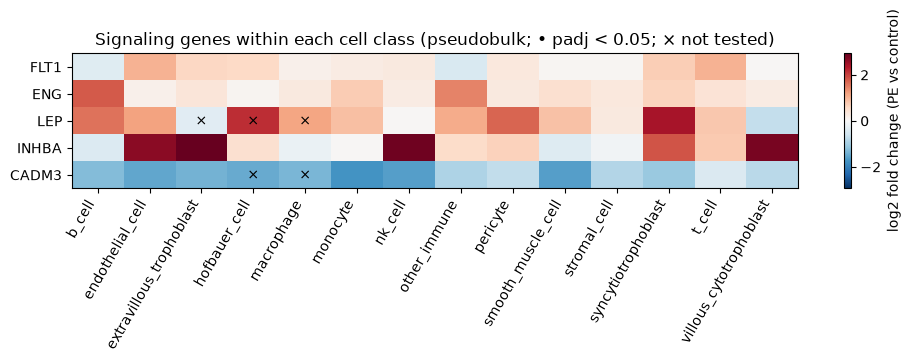

In [278]:
# 10.5a Heatmap: pseudobulk log2 fold change of the signaling genes in each cell class (8.5)
import matplotlib.pyplot as plt

lfc = focus.pivot(index="gene", columns="cell_class", values="log2FoldChange").reindex(FOCUS_GENES)
padj = focus.pivot(index="gene", columns="cell_class", values="padj").reindex(FOCUS_GENES)

lim = np.nanmax(np.abs(lfc.values))
fig, ax = plt.subplots(figsize=(10, 3.5))
im = ax.imshow(lfc.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(lfc.shape[1]), lfc.columns, rotation=60, ha="right")
ax.set_yticks(range(lfc.shape[0]), lfc.index)
# Mark cells with padj < 0.05 (•) and cells without a padj, i.e. not tested by DESeq2 (×)
for i in range(lfc.shape[0]):
    for j in range(lfc.shape[1]):
        if pd.isna(padj.iloc[i, j]):
            ax.text(j, i, "×", ha="center", va="center")
        elif padj.iloc[i, j] < 0.05:
            ax.text(j, i, "•", ha="center", va="center")
fig.colorbar(im, ax=ax, label="log2 fold change (PE vs control)")
ax.set_title("Signaling genes within each cell class (pseudobulk; • padj < 0.05; × not tested)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "fig_pseudobulk_heatmap.png", dpi=300)
plt.show()

### 10.5a Results
No focus gene reaches padj < 0.05 in any cell class, so no cell is marked •. Cells marked × were not tested by DESeq2 (8.5c); their fold changes are based on very low counts and should not be read as changes. ENG is higher and CADM3 lower in PE in all 14 cell classes (8.6).

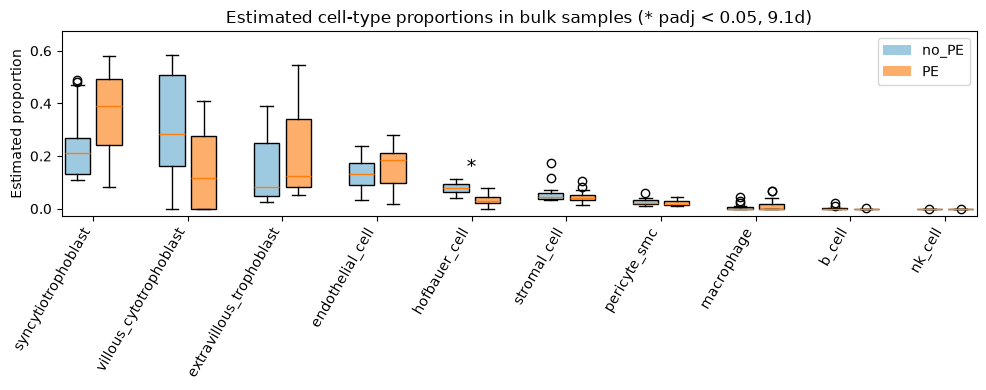

In [279]:
# 10.5b Estimated cell-type proportions by group (9.1)
from matplotlib.patches import Patch

long = bulk_props.join(comp_meta[GROUP_COLUMN]).melt(id_vars=GROUP_COLUMN, var_name="cell_class", value_name="proportion")
# Classes estimated as 0 in all samples are not shown (as in 9.1d)
classes = [c for c in bulk_props.mean().sort_values(ascending=False).index if (bulk_props[c] > 0).any()]
groups = [CONTROL, CASE]
colors = {CONTROL: "#9ecae1", CASE: "#fdae6b"}

fig, ax = plt.subplots(figsize=(10, 4))
for k, g in enumerate(groups):
    data = [long[(long["cell_class"] == c) & (long[GROUP_COLUMN] == g)]["proportion"] for c in classes]
    bp = ax.boxplot(data, positions=np.arange(len(classes)) * 3 + k, widths=0.8, patch_artist=True)
    for box in bp["boxes"]:
        box.set_facecolor(colors[g])

# Mark classes with padj < 0.05 in 9.1d (main setting), just above that class's data
padj_91d = prop_test.set_index("cell_class")["padj"]
ytop = long["proportion"].max() * 1.05
for j, c in enumerate(classes):
    if padj_91d.get(c, 1) < 0.05:
        y = long.loc[long["cell_class"] == c, "proportion"].max() + 0.005
        ax.text(j * 3 + 0.5, y, "*", ha="center", va="bottom", fontsize=14)

ax.set_xticks(np.arange(len(classes)) * 3 + 0.5, classes, rotation=60, ha="right")
ax.set_ylabel("Estimated proportion")
ax.set_ylim(top=ytop * 1.1)
ax.legend(handles=[Patch(facecolor=colors[g], label=g) for g in groups])
ax.set_title("Estimated cell-type proportions in bulk samples (* padj < 0.05, 9.1d)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "fig_cell_proportions.png", dpi=300)
plt.show()

### 10.5b Results
Only Hofbauer cells differ significantly (lower in PE; 9.1d). The plot shows unadjusted proportions, whereas the test in 9.1d adjusts for gestational age and FGR, so visible differences, such as higher syncytiotrophoblast and lower villous cytotrophoblast in PE, are not significant after adjustment. Several PE samples have an estimated villous cytotrophoblast proportion of 0, because the method does not allow negative estimates. Monocytes, T cells and other_immune are not shown because they are estimated as 0 in all samples (9.1c).